# Registration Keypoint Error & Kinematics

Merged from `fig2_02_trajectory_kp_errors` and `fig4_05_arms_tracking_kinematics`.

Computes and visualizes:
1. **STAC Registration error** — keypoint error between stac-mjx FK output (with offset model) and mocap keypoints
2. **Imitation Replay error** — keypoint error between SCAMPER imitation rollout FK output and mocap keypoints
3. **Joint angle kinematics** — comparing STAC registration and imitation rollout joint trajectories

The **offset model** is critical: stac-mjx learns per-keypoint offsets (local displacements
from the body frame origin to the marker site) during the fitting stage. These offsets must
be applied to the MuJoCo model's sites before running forward kinematics to compute marker
positions. Without offsets, the marker sites sit at body origins and errors are inflated.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import functools
from glob import glob
from pathlib import Path

import h5py
import jax
import jax.numpy as jp
import matplotlib as mpl
import matplotlib.pyplot as plt
import mujoco
import numpy as np
import pandas as pd
import seaborn as sns
from mujoco import mjx
from tqdm import tqdm

sys.path.insert(0, str(Path.cwd()))

%matplotlib inline
%config InlineBackend.figure_format='retina'

mpl.rcParams["figure.facecolor"] = "w"
mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 600
mpl.rcParams["savefig.transparent"] = True
mpl.rcParams["font.size"] = 8
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial"]
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.style.use("seaborn-v0_8-deep")

In [2]:
# === Configuration ===
# VNL model XML (fixed-shoulder, 4-DOF) — same geometry as STAC model
VNL_XML_PATH = "/root/vast/eric/vnl-playground/vnl_playground/tasks/mouse/xmls/mouse_forelimb_right.xml"
ARENA_XML_PATH = "/root/vast/eric/vnl-playground/vnl_playground/tasks/mouse/xmls/arena.xml"

# Good STACed data (fixed-shoulder, 4-DOF) — consistent qpos + kp_data + offsets
STAC_DATA_DIR = "/root/vast/eric/stac-mjx/refined_STACed_data_janelia"

# === Checkpoints ===
CHECKPOINT_PATH = "/root/vast/eric/SCAMPER/model_checkpoints/replicate-cc0.01-r4-20260411-213955-step375029760-converted"
CHECKPOINT_STEP = 0
CHECKPOINT_PATH_V2 = "/root/vast/eric/SCAMPER/model_checkpoints/r4-S5-cc06-cdc02-step800030720-converted"
CHECKPOINT_STEP_V2 = 0

ENV_CONFIG_PATH = "/root/vast/eric/SCAMPER/scamper/config/mouse-prior-janelia.yaml"
N_CLIPS = 46
SEED = 42

H5_CACHE = "notebooks/neurips_figures/data/rollouts_cc0.01_r4_step375029760.h5"
H5_CACHE_V2 = "notebooks/neurips_figures/data/rollouts_cc0.06_r4_step800030720.h5"

# Keypoint-to-body mapping (must match STAC config: Shoulder->scapula)
KP_NAMES = ["Shoulder", "Elbow", "Wrist"]
KP_BODY_PAIRS = {"Shoulder": "scapula", "Elbow": "ulna", "Wrist": "wrist"}

# Joint names for kinematics plots
JOINT_NAMES = ["sh_rotation", "sh_extension", "sh_elv", "elbow"]
JOINT_LABELS = ["SH Rot", "SH Ext", "SH Ele", "Elbow"]

# --- Raw mocap + registration paths (for shoulder reconstruction & camera overlay) ---
SESSION_ID = "A36-1_2023-07-18_16-54-01_lightOff"
RAW_DATA_DIR = "/root/vast/eric/CVAT_mouse_reach/all_data"
REFINED_CSV = "/root/vast/eric/stac-mjx/refined_reaches/A36-1_2023-07-18_16-54-01_lightOff_tone_on_off_trials_edited.csv"

# Registration file (contains rotation matrix R, MODEL_SHOULDER, etc.)
SESSION_FOLDER = os.path.join(RAW_DATA_DIR, f"{SESSION_ID}_video")
REGISTERED_H5 = os.path.join(SESSION_FOLDER, f"{SESSION_ID}_video_mujoco_registered_forelimb_right_v2.h5")
RAW_POINTS3D = os.path.join(SESSION_FOLDER, "points3d.h5")

# Camera calibration and video directory
CALIBRATION_TOML = f"/root/vast/eric/CVAT_mouse_reach/{SESSION_ID}_video_env/calibration.toml"
VIDEO_DIR = f"/root/vast/eric/CVAT_mouse_reach/{SESSION_ID}_video_env"

## 1. Load Data

Load qpos, mocap keypoints (kp_data), and offsets from the good STACed data.
This data uses a fixed-shoulder 4-DOF model.

**Important:** The registered mocap data has the shoulder pinned at the model's humerus
body position (not real mocap). We reconstruct the original shoulder trajectory from
raw `points3d.h5` data using the stored registration rotation.

In [3]:
from scipy.signal import savgol_filter

# --- Load STAC ik files ---
ik_files = sorted(glob(os.path.join(STAC_DATA_DIR, "*_ik.h5")))
assert len(ik_files) == 46, f"Expected 46 ik files, got {len(ik_files)}"

stac_qposes = []       # (46, 100, 4)
mocap_kp = []           # (46, 100, 3, 3) — registered mocap (shoulder frozen)
stac_offsets = []       # (46, 3, 3)
stac_marker_sites = []  # (46, 100, 3, 3) — FK-computed marker positions from STAC

for fp in tqdm(ik_files, desc="Loading trials"):
    with h5py.File(fp, "r") as f:
        stac_qposes.append(f["qpos"][:])
        mocap_kp.append(f["kp_data"][:].reshape(-1, 3, 3))
        stac_offsets.append(f["offsets"][:])
        stac_marker_sites.append(f["marker_sites"][:])

stac_qposes = np.stack(stac_qposes)
mocap_kp = np.stack(mocap_kp)
stac_offsets = np.stack(stac_offsets)
stac_marker_sites = np.stack(stac_marker_sites)

print(f"stac_qposes: {stac_qposes.shape}")
print(f"mocap_kp: {mocap_kp.shape}")
print(f"stac_offsets: {stac_offsets.shape}  (max magnitude: {np.abs(stac_offsets).max():.2e} m)")
print(f"stac_marker_sites: {stac_marker_sites.shape}")

# --- Load registration parameters ---
with h5py.File(REGISTERED_H5, "r") as f:
    R = np.array(f.attrs["registration_rotation"])         # (3, 3)
    MODEL_SHOULDER = np.array(f.attrs["model_shoulder"])   # (3,)
print(f"Registration rotation R: det={np.linalg.det(R):.6f}")
print(f"MODEL_SHOULDER: {MODEL_SHOULDER}")

# --- Load raw mocap and smooth ---
with h5py.File(RAW_POINTS3D, "r") as f:
    raw_tracks = f["tracks"][:]  # (frames, 1, 3, 3) in mm
raw_kps = raw_tracks[:, 0, :, :]  # (frames, 3, 3)

def smooth_positions(positions, window=15, polyorder=3):
    n_frames = positions.shape[0]
    if n_frames < window:
        window = max(polyorder + 2, n_frames // 2 * 2 + 1)
    smoothed = np.copy(positions)
    for kp in range(positions.shape[1]):
        for dim in range(3):
            smoothed[:, kp, dim] = savgol_filter(positions[:, kp, dim], window, polyorder)
    return smoothed

raw_kps_smooth = smooth_positions(raw_kps, window=15, polyorder=3)
raw_shoulder_smooth = raw_kps_smooth[:, 0, :]  # (frames, 3)
raw_shoulder_median = np.median(raw_shoulder_smooth, axis=0)
print(f"Raw shoulder: median={raw_shoulder_median} mm, std={raw_shoulder_smooth.std(axis=0)} mm")

# --- Map trials to global frames and reconstruct real shoulder ---
reach_df = pd.read_csv(REFINED_CSV)
valid_reaches = reach_df[(reach_df["start"] != 0) & (reach_df["end"] != 0)].copy()
valid_reaches["trial"] = valid_reaches["trial"].astype(int)
valid_reaches["trial_start"] = valid_reaches["trial_start"].astype(int)
valid_reaches["start"] = valid_reaches["start"].astype(int)
valid_reaches["reach_start_frame"] = valid_reaches["trial_start"] + valid_reaches["start"]

mocap_kp_real = mocap_kp.copy()  # start from registered data (elbow/wrist correct)

for trial_i, (_, reach) in enumerate(valid_reaches.iterrows()):
    start_frame = int(reach["reach_start_frame"])
    end_frame = start_frame + 100

    # Get raw smoothed shoulder for this trial's frames
    trial_shoulder = raw_shoulder_smooth[start_frame:end_frame]  # (100, 3)
    if trial_shoulder.shape[0] < 100:
        pad = 100 - trial_shoulder.shape[0]
        trial_shoulder = np.pad(trial_shoulder, ((0, pad), (0, 0)), mode="edge")

    # Reconstruct: displacement from median -> rotate by R -> add MODEL_SHOULDER
    shoulder_disp_mm = trial_shoulder - raw_shoulder_median  # (100, 3) in mm
    shoulder_disp_m = shoulder_disp_mm / 1000.0             # mm -> m
    shoulder_disp_rotated = shoulder_disp_m @ R             # (100, 3) in m
    real_shoulder = MODEL_SHOULDER + shoulder_disp_rotated # (100, 3)
    mocap_kp_real[trial_i, :, 0, :] = real_shoulder

# Compute geometric median of real shoulder positions (removes systematic offset)
from scipy.optimize import minimize

all_real_sh = mocap_kp_real[:, :, 0, :].reshape(-1, 3)  # (4600, 3)
res = minimize(
    lambda c: np.sqrt(np.sum((all_real_sh - c)**2, axis=-1)).mean(),
    x0=all_real_sh.mean(axis=0), method="Nelder-Mead",
)
shoulder_center = res.x
print(f"Shoulder center (geometric median): {shoulder_center}")
print(f"Offset from MODEL_SHOULDER (mm): {(shoulder_center - MODEL_SHOULDER) * 1000}")

# Verify
real_std = mocap_kp_real[:, :, 0, :].std(axis=1).mean(axis=0) * 1000
frozen_std = mocap_kp[:, :, 0, :].std(axis=1).mean(axis=0) * 1000
print(f"Shoulder std (mm): real={real_std}, frozen={frozen_std}")


Loading trials: 100%|██████████| 46/46 [00:00<00:00, 201.53it/s]


stac_qposes: (46, 100, 4)
mocap_kp: (46, 100, 3, 3)
stac_offsets: (46, 3, 3)  (max magnitude: 1.29e-05 m)
stac_marker_sites: (46, 100, 3, 3)
Registration rotation R: det=1.000000
MODEL_SHOULDER: [0.01404211 0.00952747 0.07198473]
Raw shoulder: median=[-11.27380924 -10.85874323 106.27595846] mm, std=[1.85697446 0.61408954 0.76656507] mm
Shoulder center (geometric median): [0.0159507  0.00937959 0.07351016]
Offset from MODEL_SHOULDER (mm): [ 1.90858841 -0.14787541  1.52543253]
Shoulder std (mm): real=[1.2015955  0.6900263  0.70041704], frozen=[1.7695129e-05 1.0244548e-05 2.9802322e-05]


## 2. Load Imitation Rollout Data

Load SCAMPER imitation rollout (or generate from checkpoint).
The rollout gives us `qposes_rollout` (simulated) and `qposes_ref` (STAC reference)
for each clip. Note: the imitation model uses the vnl-playground XML with 4 joint DOF
(no root translation), while STAC uses a 7-DOF model (3 translation + 4 joints).

In [4]:
from utils import (
    load_imitation_checkpoint,
    create_imitation_env,
    run_batched_rollouts,
    load_from_h5py,
    save_to_h5py,
)

cache_path = Path(H5_CACHE) if H5_CACHE else None

if cache_path and cache_path.exists():
    print(f"Loading cached rollouts from {cache_path}")
    rollout_data = load_from_h5py(cache_path)
else:
    ckpt = load_imitation_checkpoint(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
    env = create_imitation_env(ckpt["cfg"], env_config_path=ENV_CONFIG_PATH)
    policy_fn = ckpt["make_policy"](deterministic=True, get_activation=True)
    rollout_data = run_batched_rollouts(
        ckpt["cfg"], env, policy_fn,
        n_clips=N_CLIPS, seed=SEED,
        env_config_path=ENV_CONFIG_PATH,
    )
    rollout_data = jax.tree.map(lambda x: np.array(x), rollout_data)
    if cache_path:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        save_to_h5py(str(cache_path), rollout_data)
        print(f"Saved to {cache_path}")

print("Rollout keys:", list(rollout_data.keys()))
qposes_rollout = rollout_data["qposes_rollout"]  # (n_clips, n_steps, 4)
qposes_ref = rollout_data["qposes_ref"]           # (n_clips, n_steps, 4)
print(f"qposes_rollout: {qposes_rollout.shape}")
print(f"qposes_ref: {qposes_ref.shape}")

Loading cached rollouts from notebooks/neurips_figures/data/rollouts_cc0.01_r4_step375029760.h5
Rollout keys: ['activations', 'ctrl', 'qposes_ref', 'qposes_rollout', 'rollout_metrics', 'state_rewards']
qposes_rollout: (46, 100, 4)
qposes_ref: (46, 100, 4)


## 3. Setup Forward Kinematics (Fixed-Shoulder Model)

The fixed-shoulder model has 4 DOF: `[sh_rotation, sh_extension, sh_elv, elbow]`.
Both the STAC registration qpos and the imitation rollout qpos use this same model,
so we can compute FK directly — no root translation needed.

Note: the h5 `marker_sites` field is stale (from a different model version). We compute
marker positions from FK body positions + offsets instead.

In [5]:
# Load the fixed-shoulder model (same XML as imitation env)
fk_model = mujoco.MjModel.from_xml_path(VNL_XML_PATH)
fk_data = mujoco.MjData(fk_model)

# Body IDs for keypoints (Shoulder->scapula, matching STAC config)
kp_body_ids = {}
for kp_name in KP_NAMES:
    body_name = KP_BODY_PAIRS[kp_name]
    body_id = mujoco.mj_name2id(fk_model, mujoco.mjtObj.mjOBJ_BODY, body_name)
    kp_body_ids[kp_name] = body_id
    print(f"  {kp_name} -> body '{body_name}' (id={body_id})")

print(f"\nModel joints: {[mujoco.mj_id2name(fk_model, mujoco.mjtObj.mjOBJ_JOINT, i) for i in range(fk_model.njnt)]}")
print(f"Model qpos dim: {fk_model.nq}")


  Shoulder -> body 'scapula' (id=2)
  Elbow -> body 'ulna' (id=4)
  Wrist -> body 'wrist' (id=5)

Model joints: ['sh_elv', 'sh_extension', 'sh_rotation', 'elbow']
Model qpos dim: 4


In [6]:
def compute_markers_from_qpos(model, data, qpos_batch, offsets, kp_body_ids, shoulder_center=None):
    """Compute global marker positions from qpos using MuJoCo FK with offsets.

    For the shoulder keypoint, uses a fixed shoulder_center position
    (geometric median of reconstructed real shoulder positions).
    For elbow/wrist, uses the mapped body + learned STAC offset.
    """
    body_ids = [kp_body_ids[name] for name in KP_NAMES]
    n_kp = len(body_ids)
    markers = np.zeros((qpos_batch.shape[0], n_kp, 3))

    for t in range(qpos_batch.shape[0]):
        data.qpos[:] = qpos_batch[t]
        mujoco.mj_kinematics(model, data)
        mujoco.mj_comPos(model, data)
        for ki, bid in enumerate(body_ids):
            if KP_NAMES[ki] == "Shoulder":
                # Use corrected shoulder center (geometric median of real shoulder cloud)
                markers[t, ki] = shoulder_center
            else:
                xpos = data.xpos[bid]
                xmat = data.xmat[bid].reshape(3, 3)
                markers[t, ki] = xpos + xmat @ offsets[ki]

    return markers


def compute_kp_errors_per_trial(markers, kp_data):
    """Compute per-keypoint and total Euclidean errors in mm."""
    diffs = markers - kp_data
    distances = np.sqrt(np.sum(diffs**2, axis=-1)) * 1000  # to mm
    total = distances.mean(axis=-1, keepdims=True)
    return np.concatenate([distances, total], axis=-1)


# Timing constants from env config
MOCAP_HZ = 200
CTRL_DT = 0.0025
CLIP_LENGTH = 50  # mocap frames used by imitation env
STEPS_PER_FRAME = int((1.0 / MOCAP_HZ) / CTRL_DT)  # 2


def rollout_to_stac_indices(n_rollout_steps):
    """Map each rollout timestep to its corresponding stac (mocap) frame index."""
    return np.minimum(
        np.arange(n_rollout_steps) // STEPS_PER_FRAME,
        CLIP_LENGTH - 1,
    )


def get_aligned_mocap_kp(kp_trial, n_rollout_steps):
    """Align mocap keypoints to rollout timesteps using precise frame mapping."""
    stac_idx = rollout_to_stac_indices(n_rollout_steps)
    return kp_trial[stac_idx]

## 4. Compute Keypoint Errors

**STAC Registration errors**: FK from stac qpos (4-DOF) with offsets vs mocap kp_data.

**Imitation Replay errors**: FK from rollout qpos (4-DOF) vs mocap kp_data.

In [7]:
# --- STAC Registration errors (marker_sites vs real mocap with shoulder) ---
n_trials = stac_qposes.shape[0]
stac_errors_list = []

for trial_idx in tqdm(range(n_trials), desc="Computing STAC registration errors"):
    # For STAC, compute FK markers (uses humerus for shoulder)
    markers = compute_markers_from_qpos(
        fk_model, fk_data, stac_qposes[trial_idx], stac_offsets[trial_idx], kp_body_ids, shoulder_center=shoulder_center
    )
    markers_clip = markers[:CLIP_LENGTH]
    kp_clip = mocap_kp_real[trial_idx, :CLIP_LENGTH]
    trial_errors = compute_kp_errors_per_trial(markers_clip, kp_clip)
    stac_errors_list.append(trial_errors)

stac_errors_flat = np.concatenate(stac_errors_list, axis=0)

print(f"STAC registration error (mm):")
print(f"  Total: mean={stac_errors_flat[:, -1].mean():.2f}, median={np.median(stac_errors_flat[:, -1]):.2f}")
for i, name in enumerate(KP_NAMES):
    print(f"  {name}: mean={stac_errors_flat[:, i].mean():.2f} mm")

Computing STAC registration errors:   0%|          | 0/46 [00:00<?, ?it/s]

Computing STAC registration errors: 100%|██████████| 46/46 [00:00<00:00, 596.37it/s]

STAC registration error (mm):
  Total: mean=0.71, median=0.49
  Shoulder: mean=1.76 mm
  Elbow: mean=0.14 mm
  Wrist: mean=0.22 mm


In [8]:
# --- Imitation Replay errors (FK from rollout qpos vs real mocap with shoulder) ---
imitation_errors_list = []

for trial_idx in tqdm(range(n_trials), desc="Computing imitation FK errors"):
    rollout_qpos = qposes_rollout[trial_idx]
    offsets_trial = stac_offsets[trial_idx]
    kp_trial = mocap_kp_real[trial_idx]

    markers = compute_markers_from_qpos(
        fk_model, fk_data, rollout_qpos, offsets_trial, kp_body_ids, shoulder_center=shoulder_center
    )

    kp_aligned = get_aligned_mocap_kp(kp_trial, markers.shape[0])
    trial_errors = compute_kp_errors_per_trial(markers, kp_aligned)
    imitation_errors_list.append(trial_errors)

imitation_errors_flat = np.concatenate(imitation_errors_list, axis=0)

print(f"\nImitation replay error (mm):")
print(f"  Total: mean={imitation_errors_flat[:, -1].mean():.2f}, median={np.median(imitation_errors_flat[:, -1]):.2f}")
for i, name in enumerate(KP_NAMES):
    print(f"  {name}: mean={imitation_errors_flat[:, i].mean():.2f} mm")

Computing imitation FK errors:   0%|          | 0/46 [00:00<?, ?it/s]

Computing imitation FK errors: 100%|██████████| 46/46 [00:00<00:00, 779.81it/s]


Imitation replay error (mm):
  Total: mean=1.23, median=1.06
  Shoulder: mean=1.76 mm
  Elbow: mean=0.85 mm
  Wrist: mean=1.08 mm


## 4b. Load Second Checkpoint (cc=0.06)

Repeat rollout loading for the cc=0.06 checkpoint to compare both.

In [9]:
# === Second checkpoint: cc=0.06 ===
cache_path_v2 = Path(H5_CACHE_V2) if H5_CACHE_V2 else None

if cache_path_v2 and cache_path_v2.exists():
    print(f"Loading cached rollouts from {cache_path_v2}")
    rollout_data_v2 = load_from_h5py(cache_path_v2)
else:
    print(f"Generating rollouts from: {CHECKPOINT_PATH_V2}")
    ckpt_v2 = load_imitation_checkpoint(CHECKPOINT_PATH_V2, step=CHECKPOINT_STEP_V2)
    env_v2 = create_imitation_env(ckpt_v2["cfg"], env_config_path=ENV_CONFIG_PATH)
    policy_fn_v2 = ckpt_v2["make_policy"](deterministic=True, get_activation=True)
    rollout_data_v2 = run_batched_rollouts(
        ckpt_v2["cfg"], env_v2, policy_fn_v2,
        n_clips=N_CLIPS, seed=SEED,
        env_config_path=ENV_CONFIG_PATH,
    )
    rollout_data_v2 = jax.tree.map(lambda x: np.array(x), rollout_data_v2)
    if cache_path_v2:
        cache_path_v2.parent.mkdir(parents=True, exist_ok=True)
        save_to_h5py(str(cache_path_v2), rollout_data_v2)
        print(f"Saved to {cache_path_v2}")

qposes_rollout_v2 = rollout_data_v2["qposes_rollout"]
qposes_ref_v2 = rollout_data_v2["qposes_ref"]
print(f"V2 qposes_rollout: {qposes_rollout_v2.shape}")
print(f"V2 qposes_ref: {qposes_ref_v2.shape}")

# Diagnostic: verify V2 is different from V1
v1v2_same = np.allclose(qposes_rollout, qposes_rollout_v2, atol=1e-4)
print(f"\nV1 vs V2 rollouts identical: {v1v2_same}")
if not v1v2_same:
    diff = np.abs(qposes_rollout - qposes_rollout_v2).mean()
    print(f"Mean abs difference: {np.degrees(diff):.2f} deg")
else:
    print("WARNING: V1 and V2 produced identical rollouts -- check checkpoints!")

Loading cached rollouts from notebooks/neurips_figures/data/rollouts_cc0.06_r4_step800030720.h5
V2 qposes_rollout: (46, 100, 4)
V2 qposes_ref: (46, 100, 4)

V1 vs V2 rollouts identical: False
Mean abs difference: 1.48 deg


In [10]:
# --- Imitation Replay errors for V2 (cc=0.06) vs real mocap with shoulder ---
imitation_errors_v2_list = []

for trial_idx in tqdm(range(n_trials), desc="Computing V2 imitation FK errors"):
    rollout_qpos = qposes_rollout_v2[trial_idx]
    offsets_trial = stac_offsets[trial_idx]
    kp_trial = mocap_kp_real[trial_idx]

    markers = compute_markers_from_qpos(
        fk_model, fk_data, rollout_qpos, offsets_trial, kp_body_ids, shoulder_center=shoulder_center
    )

    kp_aligned = get_aligned_mocap_kp(kp_trial, markers.shape[0])
    trial_errors = compute_kp_errors_per_trial(markers, kp_aligned)
    imitation_errors_v2_list.append(trial_errors)

imitation_errors_v2_flat = np.concatenate(imitation_errors_v2_list, axis=0)

print(f"\nV2 imitation replay error (mm):")
print(f"  Total: mean={imitation_errors_v2_flat[:, -1].mean():.2f}, median={np.median(imitation_errors_v2_flat[:, -1]):.2f}")
for i, name in enumerate(KP_NAMES):
    print(f"  {name}: mean={imitation_errors_v2_flat[:, i].mean():.2f} mm")

Computing V2 imitation FK errors:   0%|          | 0/46 [00:00<?, ?it/s]

Computing V2 imitation FK errors: 100%|██████████| 46/46 [00:00<00:00, 739.14it/s]


V2 imitation replay error (mm):
  Total: mean=1.39, median=1.30
  Shoulder: mean=1.76 mm
  Elbow: mean=1.03 mm
  Wrist: mean=1.38 mm


## 4c. Camera Views with Reprojected Keypoints & Model Poses

/tmp/ipykernel_475909/3914608838.py:96: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  frame_bright = np.clip(frame_img.astype(np.float32) * 1.8 + 30, 0, 255).astype(np.uint8)


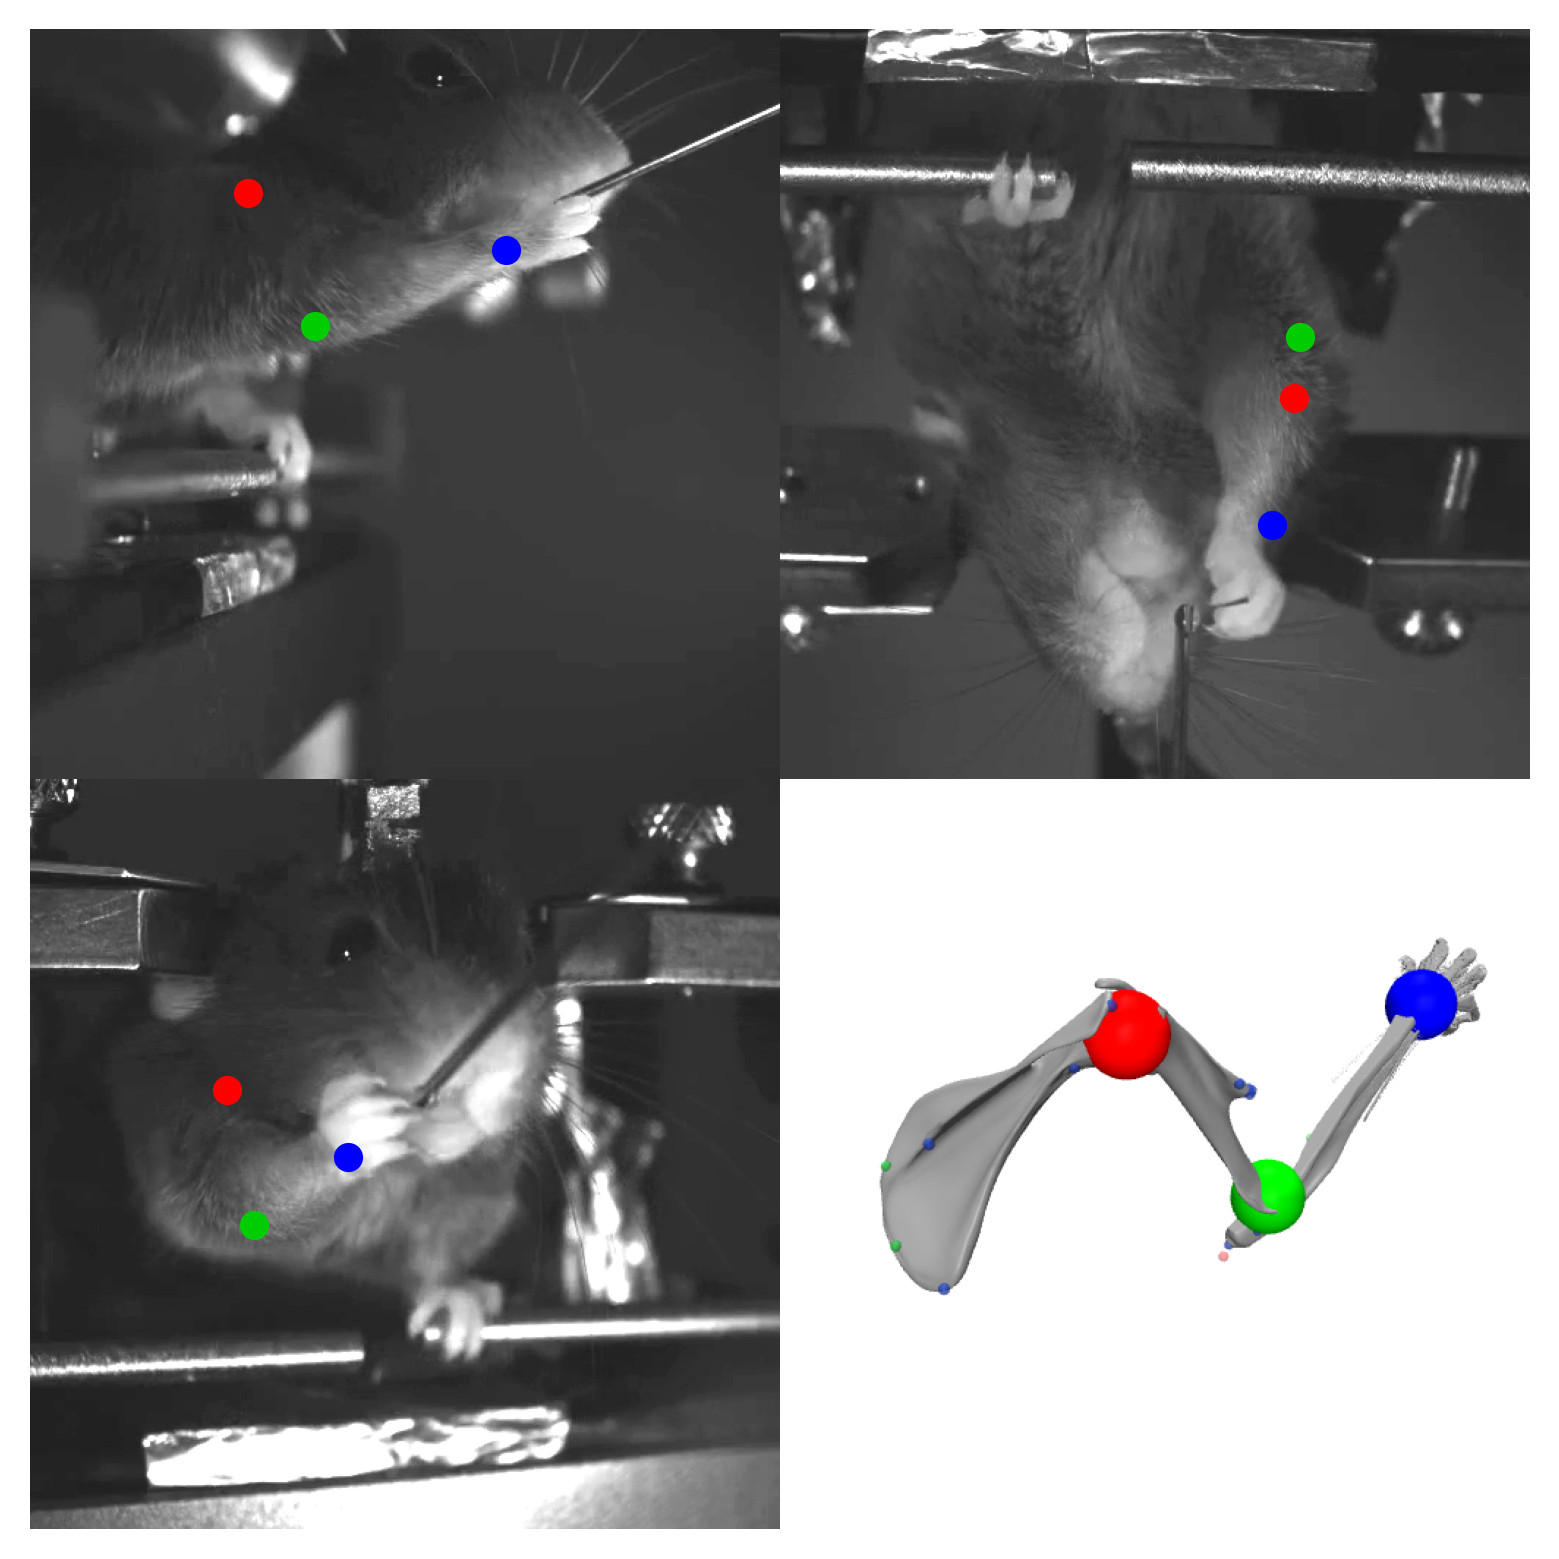

In [11]:
# --- Camera views + MuJoCo model with keypoint spheres (2x2 grid) ---
import tomllib
import imageio
from scipy.spatial.transform import Rotation as RotLib


class CameraParams:
    """Minimal camera params with numpy-only projection."""
    def __init__(self, name, size, K, dist, rvec, tvec):
        self.name, self.size = name, size
        self.K = np.array(K, dtype=np.float64)
        self.dist = np.array(dist, dtype=np.float64)
        self.rvec = np.array(rvec, dtype=np.float64)
        self.tvec = np.array(tvec, dtype=np.float64)

    @property
    def R(self):
        return RotLib.from_rotvec(self.rvec).as_matrix()

    @property
    def projection_matrix(self):
        Rt = np.hstack([self.R, self.tvec.reshape(3, 1)])
        return self.K @ Rt

    def project_points(self, points_3d):
        P = self.projection_matrix
        pts_h = np.hstack([points_3d, np.ones((len(points_3d), 1))])
        projected = (P @ pts_h.T).T
        return projected[:, :2] / projected[:, 2:3]


def load_calibration(toml_path):
    with open(toml_path, "rb") as f:
        cal = tomllib.load(f)
    cameras = []
    cam_idx = 0
    while f"cam_{cam_idx}" in cal:
        s = cal[f"cam_{cam_idx}"]
        cameras.append(CameraParams(
            name=s["name"], size=tuple(s["size"]),
            K=s["matrix"], dist=s["distortions"],
            rvec=s["rotation"], tvec=s["translation"],
        ))
        cam_idx += 1
    return cameras


def mujoco_to_calibration(points_mj, model_shoulder, R_total, shoulder_calib_mm):
    centered = points_mj - model_shoulder
    rotated = centered @ R_total.T
    scaled = rotated * 1000.0
    return scaled + shoulder_calib_mm


# ── Load calibration and registration ──
cameras = load_calibration(CALIBRATION_TOML)

with h5py.File(REGISTERED_H5, "r") as f:
    R_reg = np.array(f.attrs["registration_rotation"])
    model_shoulder_reg = np.array(f.attrs["registration_translation"])

video_files = {}
for cam in cameras:
    cam_dir = os.path.join(VIDEO_DIR, cam.name.replace("cam", "Cam"))
    vids = sorted(glob(os.path.join(cam_dir, "*.mp4")))
    if vids:
        video_files[cam.name] = vids[0]

# ── Pick a single frame ~20 frames into the reach ──
VIZ_TRIAL = 0
VIZ_FRAME = 20  # ~100ms into reach at 200Hz

trial_reach = valid_reaches.iloc[VIZ_TRIAL]
video_start_frame = int(trial_reach["reach_start_frame"])
global_frame = video_start_frame + VIZ_FRAME

# Keypoint colors: Shoulder=red, Elbow=green, Wrist=blue
KP_COLORS = [(1.0, 0.0, 0.0), (0.0, 0.8, 0.0), (0.0, 0.0, 1.0)]

# 3D keypoints — use raw smoothed mocap directly (already in calibration frame, mm)
kp_calib_direct = raw_kps_smooth[global_frame]  # (3, 3) in mm

# ── 2x2 figure ──
fig, axes = plt.subplots(2, 2, figsize=(5, 5), gridspec_kw={'wspace': 0, 'hspace': 0})

# Top-left, top-right, bottom-left: 3 camera views
cam_positions = [(0, 0), (0, 1), (1, 0)]
for (row, col), cam in zip(cam_positions, cameras):
    reader = imageio.get_reader(video_files[cam.name])
    frame_img = reader.get_data(global_frame)
    reader.close()

    kp_2d = cam.project_points(kp_calib_direct)

    # Brighten camera image for visibility
    frame_bright = np.clip(frame_img.astype(np.float32) * 1.8 + 30, 0, 255).astype(np.uint8)
    axes[row, col].imshow(frame_bright)
    for ki in range(3):
        axes[row, col].plot(kp_2d[ki, 0], kp_2d[ki, 1], "o",
                            color=KP_COLORS[ki], markersize=7, markeredgewidth=0)
    axes[row, col].axis("off")

# Bottom-right: High-res MuJoCo model with colored keypoint spheres
HIRES_XML = "/root/vast/eric/janelia_model/skeleton_stls_object_coordinates_hand/mouse_forelimb_right.xml"
hires_spec = mujoco.MjSpec.from_file(HIRES_XML)
hires_spec.visual.global_.offwidth = 1024
hires_spec.visual.global_.offheight = 1024

hires_spec.worldbody.add_camera(
    name="render_cam",
    pos=[0.015, -0.025, 0.068],
    xyaxes=[1, 0, 0, 0, 0, 1],
    fovy=40,
)

render_model = hires_spec.compile()
render_data = mujoco.MjData(render_model)
render_data.qpos[:] = stac_qposes[VIZ_TRIAL, VIZ_FRAME]
mujoco.mj_forward(render_model, render_data)

# White background + bright lighting
render_model.vis.rgba.fog[:] = [1, 1, 1, 1]
render_model.vis.headlight.diffuse[:] = [0.8, 0.8, 0.8]
render_model.vis.headlight.ambient[:] = [0.4, 0.4, 0.4]
render_model.vis.headlight.specular[:] = [0.3, 0.3, 0.3]

renderer = mujoco.Renderer(render_model, height=512, width=512)
scene_opt = mujoco.MjvOption()
scene_opt.flags[mujoco.mjtVisFlag.mjVIS_TENDON] = False
renderer.update_scene(render_data, camera="render_cam", scene_option=scene_opt)
renderer.scene.flags[mujoco.mjtRndFlag.mjRND_FOG] = True

# Keypoint positions: humerus=shoulder, ulna=elbow, ulna+offset=wrist
kp_render_bodies = {"Shoulder": "humerus", "Elbow": "ulna", "Wrist": "ulna"}
kp_world = []
for kp_name in KP_NAMES:
    bid = mujoco.mj_name2id(render_model, mujoco.mjtObj.mjOBJ_BODY, kp_render_bodies[kp_name])
    pos = render_data.xpos[bid].copy()
    if kp_name == "Wrist":
        xmat = render_data.xmat[bid].reshape(3, 3)
        pos = pos + xmat @ np.array([0, 0.01092, 0])
    kp_world.append(pos)

# Set white background
render_model.vis.rgba.fog[:] = [1, 1, 1, 1]
render_model.vis.headlight.diffuse[:] = [0.8, 0.8, 0.8]
render_model.vis.headlight.ambient[:] = [0.4, 0.4, 0.4]
render_model.vis.headlight.specular[:] = [0.3, 0.3, 0.3]
render_model.vis.map.znear = 0.001
render_model.vis.map.zfar = 1.0


# Add RGB spheres at keypoint positions
KP_RGBA = [[1, 0, 0, 1], [0, 0.8, 0, 1], [0, 0, 1, 1]]
for ki in range(3):
    mujoco.mjv_initGeom(
        renderer.scene.geoms[renderer.scene.ngeom],
        type=mujoco.mjtGeom.mjGEOM_SPHERE,
        size=[0.0015, 0, 0],
        pos=kp_world[ki],
        mat=np.eye(3).flatten(),
        rgba=np.array(KP_RGBA[ki], dtype=np.float32),
    )
    renderer.scene.ngeom += 1

pixels = renderer.render()
renderer.close()

axes[1, 1].imshow(pixels)
axes[1, 1].axis("off")

fig.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)
plt.savefig("figures/camera_model_panel.pdf",
            bbox_inches="tight", pad_inches=0, dpi=300)
plt.savefig("figures/camera_model_panel.png",
            bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()


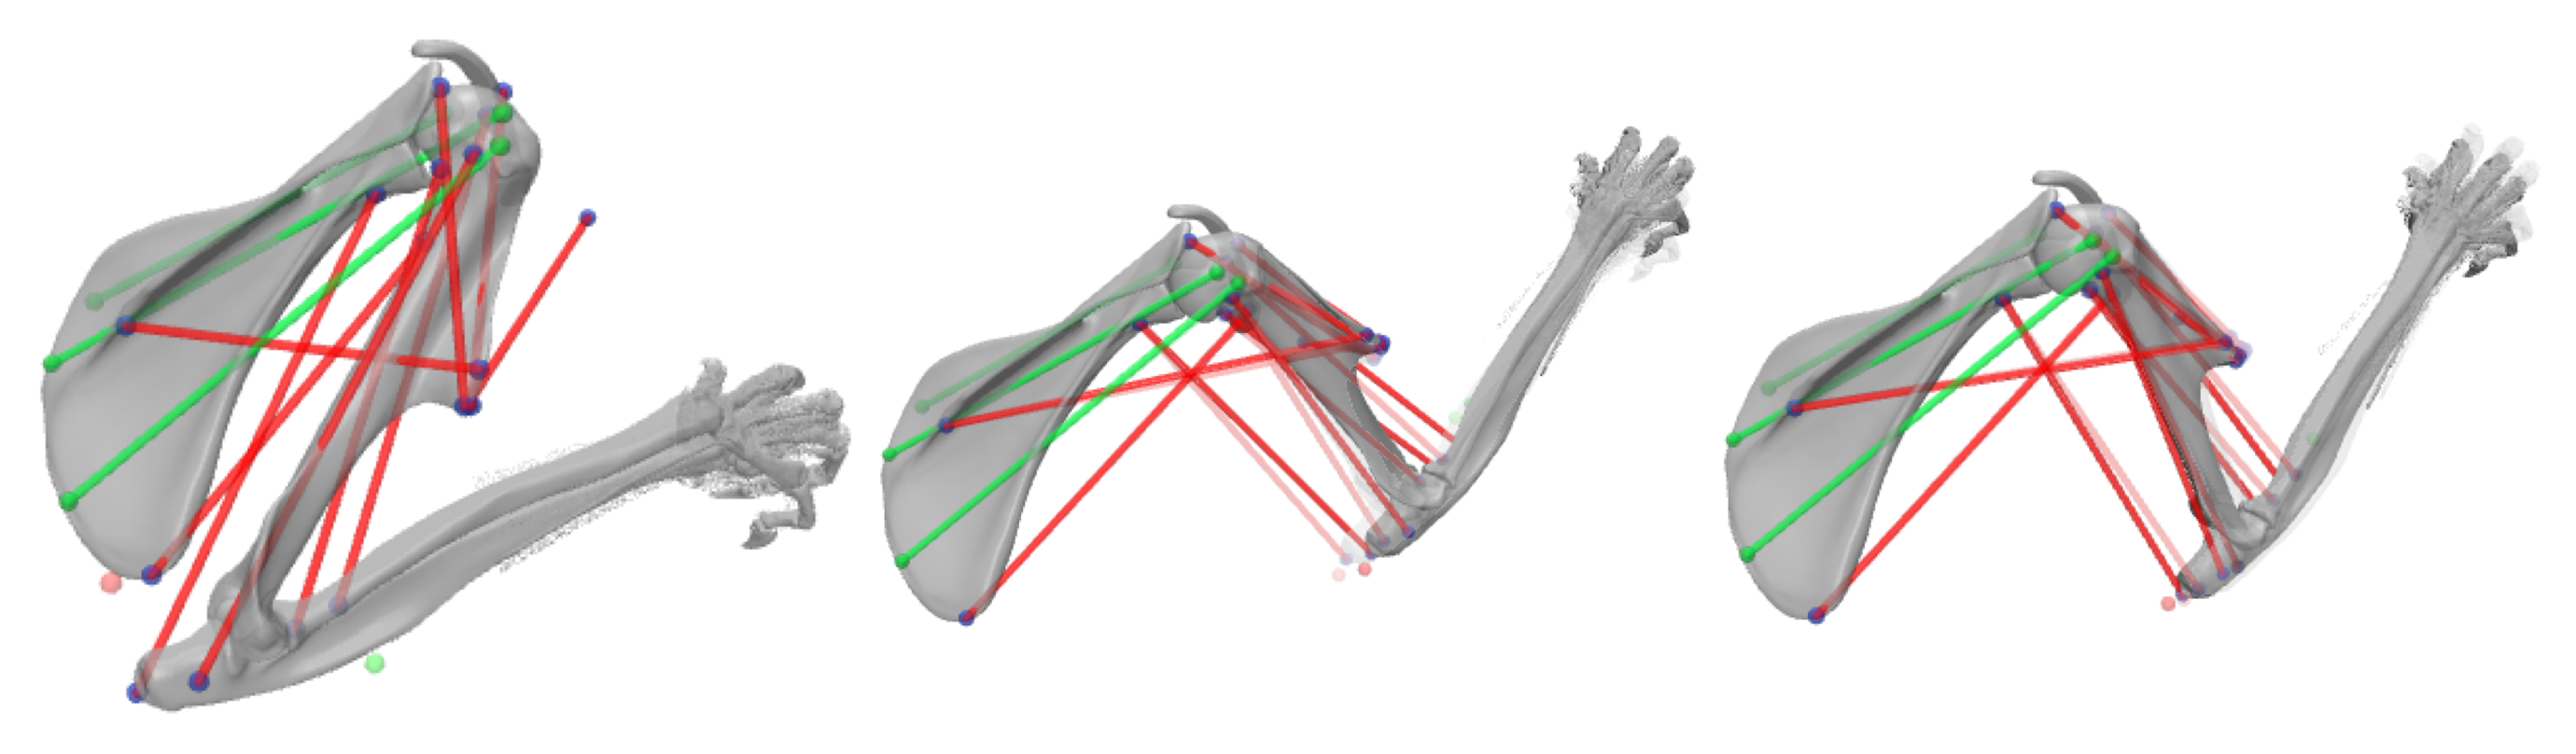

In [12]:
# --- Ghost render: imitation (solid) + reference (ghost) at 3 reach stages ---
# Uses the high-res musculoskeletal model with muscles (tendons) visible
HIRES_XML = "/root/vast/eric/janelia_model/skeleton_stls_object_coordinates_hand/mouse_forelimb_right.xml"

VIZ_GHOST_TRIAL = 0
GHOST_FRAMES = [0, 20, 50]  # start, mid-reach, late-reach (mocap frames)

CAM_PARAMS = dict(
    name="render_cam",
    pos=[0.015, -0.025, 0.068],
    xyaxes=[1, 0, 0, 0, 0, 1],
    fovy=40,
)


def render_dual_pose(stac_qpos, imit_qpos):
    """Render imitation (solid) + reference (transparent ghost) with muscles."""
    # --- Imitation (solid) ---
    hires_spec = mujoco.MjSpec.from_file(HIRES_XML)
    hires_spec.visual.global_.offwidth = 1024
    hires_spec.visual.global_.offheight = 1024
    hires_spec.worldbody.add_camera(**CAM_PARAMS)
    model_imit = hires_spec.compile()
    data_imit = mujoco.MjData(model_imit)
    data_imit.qpos[:] = imit_qpos
    mujoco.mj_forward(model_imit, data_imit)

    model_imit.vis.rgba.fog[:] = [1, 1, 1, 1]
    model_imit.vis.headlight.diffuse[:] = [0.8, 0.8, 0.8]
    model_imit.vis.headlight.ambient[:] = [0.4, 0.4, 0.4]
    model_imit.vis.headlight.specular[:] = [0.3, 0.3, 0.3]

    renderer = mujoco.Renderer(model_imit, height=512, width=512)
    scene_opt = mujoco.MjvOption()
    # Show tendons (muscles)!
    renderer.update_scene(data_imit, camera="render_cam", scene_option=scene_opt)
    renderer.scene.flags[mujoco.mjtRndFlag.mjRND_FOG] = True
    imit_pixels = renderer.render().copy()
    renderer.close()

    # --- Reference (ghost) ---
    hires_spec2 = mujoco.MjSpec.from_file(HIRES_XML)
    hires_spec2.visual.global_.offwidth = 1024
    hires_spec2.visual.global_.offheight = 1024
    hires_spec2.worldbody.add_camera(**CAM_PARAMS)
    model_ref = hires_spec2.compile()
    data_ref = mujoco.MjData(model_ref)
    data_ref.qpos[:] = stac_qpos
    mujoco.mj_forward(model_ref, data_ref)

    for gi in range(model_ref.ngeom):
        model_ref.geom_rgba[gi, 3] = 0.25

    model_ref.vis.rgba.fog[:] = [1, 1, 1, 1]
    model_ref.vis.headlight.diffuse[:] = [0.8, 0.8, 0.8]
    model_ref.vis.headlight.ambient[:] = [0.4, 0.4, 0.4]
    model_ref.vis.headlight.specular[:] = [0.3, 0.3, 0.3]

    renderer2 = mujoco.Renderer(model_ref, height=512, width=512)
    renderer2.update_scene(data_ref, camera="render_cam", scene_option=scene_opt)
    renderer2.scene.flags[mujoco.mjtRndFlag.mjRND_FOG] = True
    ref_pixels = renderer2.render().copy()
    renderer2.close()

    # Composite: overlay ghost onto solid
    imit_f = imit_pixels.astype(np.float32)
    ref_f = ref_pixels.astype(np.float32)
    is_bg = np.all(ref_pixels > 240, axis=-1)
    alpha = np.where(is_bg, 0.0, 0.35)[..., np.newaxis]
    composite = imit_f * (1 - alpha) + ref_f * alpha
    return np.clip(composite, 0, 255).astype(np.uint8)


# Render 3 timepoints
ghost_panels = []
for fi, frame_idx in enumerate(GHOST_FRAMES):
    rollout_step = min(frame_idx * STEPS_PER_FRAME, qposes_rollout.shape[1] - 1)
    stac_q = stac_qposes[VIZ_GHOST_TRIAL, frame_idx]
    imit_q = qposes_rollout[VIZ_GHOST_TRIAL, rollout_step]
    ghost_panels.append(render_dual_pose(stac_q, imit_q))

# Crop whitespace from each panel before plotting
def autocrop(img, bg_thresh=240, pad=5):
    """Crop white borders from an image."""
    mask = np.any(img < bg_thresh, axis=-1)
    rows = np.any(mask, axis=1)
    cols = np.any(mask, axis=0)
    rmin, rmax = np.where(rows)[0][[0, -1]]
    cmin, cmax = np.where(cols)[0][[0, -1]]
    rmin, cmin = max(0, rmin - pad), max(0, cmin - pad)
    rmax, cmax = min(img.shape[0], rmax + pad), min(img.shape[1], cmax + pad)
    return img[rmin:rmax+1, cmin:cmax+1]

cropped = [autocrop(p) for p in ghost_panels]

# Stack horizontally with minimal gap
fig, axes = plt.subplots(1, 3, figsize=(9, 3), gridspec_kw={"wspace": 0.01})
for i, img in enumerate(cropped):
    axes[i].imshow(img)
    axes[i].axis("off")

fig.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0.01)
plt.savefig("figures/ghost_poses.pdf",
            bbox_inches="tight", pad_inches=0, dpi=300)
plt.savefig("figures/ghost_poses.png",
            bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()

## 5. Keypoint Error Boxplots

Two separate plots — one for each control cost variant — comparing STAC Registration
vs Imitation Replay keypoint errors against the **real mocap** (with moving shoulder).

In [13]:
def build_error_dataframe(stac_errors_flat, imitation_errors_flat):
    """Build a DataFrame for seaborn boxplot from error arrays."""
    part_names = KP_NAMES + ["Total"]
    rows = []
    for i, part in enumerate(part_names):
        for err in stac_errors_flat[:, i]:
            rows.append({"Body Part": part.lower(), "Keypoint Error (mm)": err, "Method": "STAC Registration"})
        for err in imitation_errors_flat[:, i]:
            rows.append({"Body Part": part.lower(), "Keypoint Error (mm)": err, "Method": "Imitation Replay"})
    return pd.DataFrame(rows)


def plot_kp_error_boxplot(df, save_path=None):
    """Horizontal boxplot of keypoint errors by body part and method."""
    fig, ax = plt.subplots(figsize=(3, 3))

    sns.boxplot(
        data=df,
        x="Keypoint Error (mm)",
        y="Body Part",
        hue="Method",
        palette={"STAC Registration": "orange", "Imitation Replay": "skyblue"},
        orient="h",
        showfliers=False,
        ax=ax,
        order=["total", "shoulder", "elbow", "wrist"],
    )

    ax.set_xlabel("Keypoint Error (mm)", fontsize=8)
    ax.set_ylabel("")
    ax.tick_params(axis="both", which="major", labelsize=8, width=0.8, length=5)

    for spine in ax.spines.values():
        spine.set_linewidth(1)

    ax.invert_yaxis()

    legend_x, legend_y = 0.15, 1.15
    ax.text(legend_x, legend_y, "STAC Registration", color="#FFA500",
            fontsize=8, fontweight="bold", transform=ax.transAxes, va="top", ha="center")
    ax.text(legend_x, legend_y - 0.08, "Imitation Replay", color="#87CEEB",
            fontsize=8, fontweight="bold", transform=ax.transAxes, va="top", ha="center")
    ax.legend().remove()

    sns.despine(ax=ax, top=True, right=True, left=True, bottom=False)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
        print(f"Saved to {save_path}")
    plt.show()


Saved to notebooks/neurips_figures/data/kp_errors_cc0.01.pdf


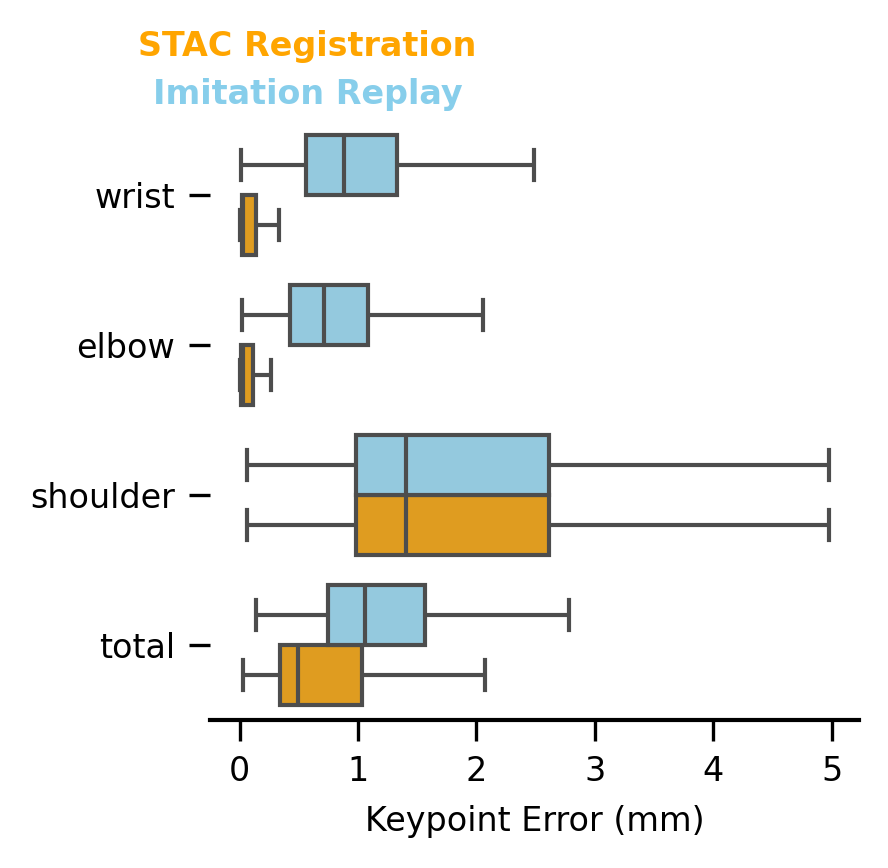

In [14]:
# --- Plot 1: cc=0.01 ---
df_v1 = build_error_dataframe(stac_errors_flat, imitation_errors_flat)
plot_kp_error_boxplot(
    df_v1,
    save_path="notebooks/neurips_figures/data/kp_errors_cc0.01.pdf",
)


Saved to notebooks/neurips_figures/data/kp_errors_cc0.06.pdf


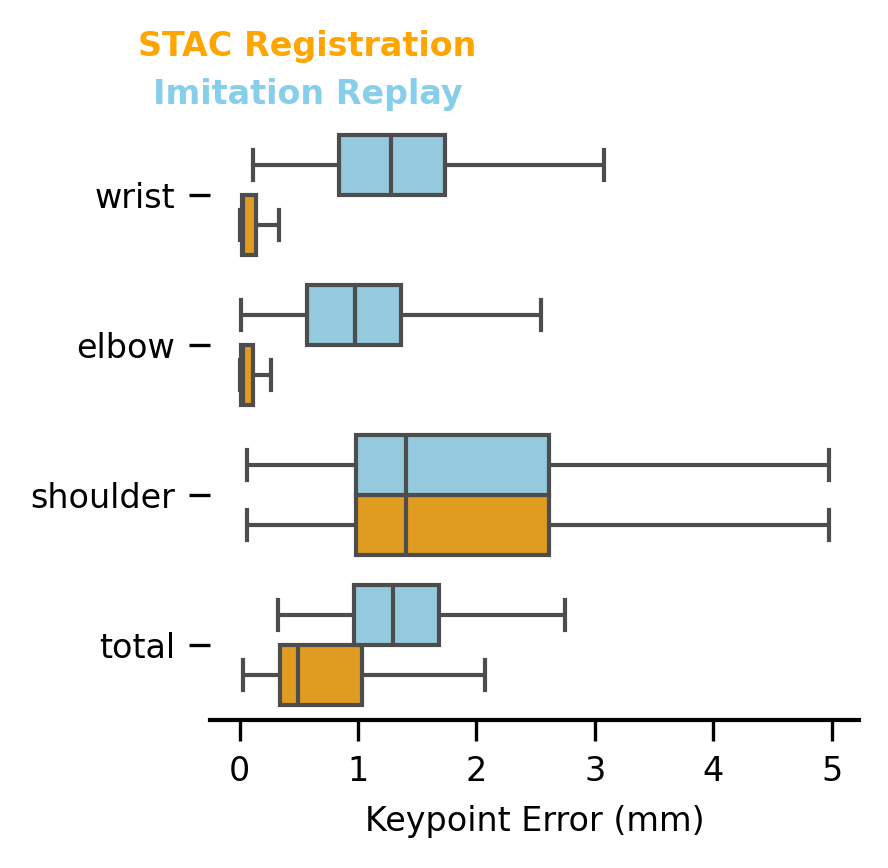

In [15]:
# --- Plot 2: cc=0.06 ---
df_v2 = build_error_dataframe(stac_errors_flat, imitation_errors_v2_flat)
plot_kp_error_boxplot(
    df_v2,
    save_path="notebooks/neurips_figures/data/kp_errors_cc0.06.pdf",
)


## 6. Joint Angle Kinematics Comparison

For a single clip, plot the 4 joint angles (SH Rot, SH Ext, SH Ele, Elbow) over time,
comparing STAC Registration (reference) vs Imitation Replay.
Separate subplots for each control cost variant.

In [16]:
def plot_kinematics(qposes_ref, qposes_rollout, clip_id, title, ctrl_dt=0.0025, save_path=None):
    """Plot joint angle kinematics for a single clip.

    Args:
        qposes_ref: (n_clips, n_steps, 4) reference joint angles.
        qposes_rollout: (n_clips, n_steps, 4) rollout joint angles.
        clip_id: Which clip to plot.
        title: Plot title (e.g., "ctrl_cost=0.02").
        ctrl_dt: Control timestep for time axis.
        save_path: Optional path to save PDF.
    """
    fig, axes = plt.subplots(len(JOINT_NAMES), 1, figsize=(3, 3), sharex=True)

    ref = qposes_ref[clip_id]      # (n_steps, 4)
    rollout = qposes_rollout[clip_id]  # (n_steps, 4)
    n_steps = ref.shape[0]
    time_ms = np.arange(n_steps) * ctrl_dt * 1e3  # milliseconds

    # Global y limits across all joints
    all_angles = np.concatenate([np.degrees(ref), np.degrees(rollout)], axis=0)
    y_min, y_max = all_angles.min() - 5, all_angles.max() + 5

    for i, (joint_label, ax) in enumerate(zip(JOINT_LABELS, axes)):
        ref_deg = np.degrees(ref[:, i])
        rollout_deg = np.degrees(rollout[:, i])

        sns.lineplot(x=time_ms, y=ref_deg, ax=ax, color="orange",
                     label="STAC Registration", linewidth=2)
        sns.lineplot(x=time_ms, y=rollout_deg, ax=ax, color="skyblue",
                     label="Imitation Replay", linewidth=2)
        ax.fill_between(time_ms, ref_deg, rollout_deg, alpha=0.2, color="red")

        ax.set_ylabel(joint_label, fontsize=8)
        ax.set_ylim(y_min, y_max)
        ax.grid(False)

        if i < len(JOINT_NAMES) - 1:
            sns.despine(ax=ax, top=True, right=True, bottom=True, left=False)
            ax.tick_params(bottom=False, labelbottom=False)
            ax.spines["left"].set_position(("outward", 5))
        else:
            sns.despine(ax=ax, top=True, right=True, bottom=False, left=False)
            ax.spines["bottom"].set_bounds(0, time_ms[-1])
            ax.spines["left"].set_position(("outward", 5))
            ax.spines["bottom"].set_position(("outward", 5))

        if ax.get_legend():
            ax.get_legend().remove()

    fig.text(-0.02, 0.5, "Joint Angle (degrees)", va="center", rotation="vertical",
             fontsize=8, fontweight="bold")
    fig.suptitle(title, fontsize=9, fontweight="bold", y=1.02)

    axes[-1].set_xlabel("Time (milliseconds)", fontsize=8)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
        print(f"Saved to {save_path}")
    plt.show()

Saved to notebooks/neurips_figures/data/kinematics_cc0.01_clip0.pdf


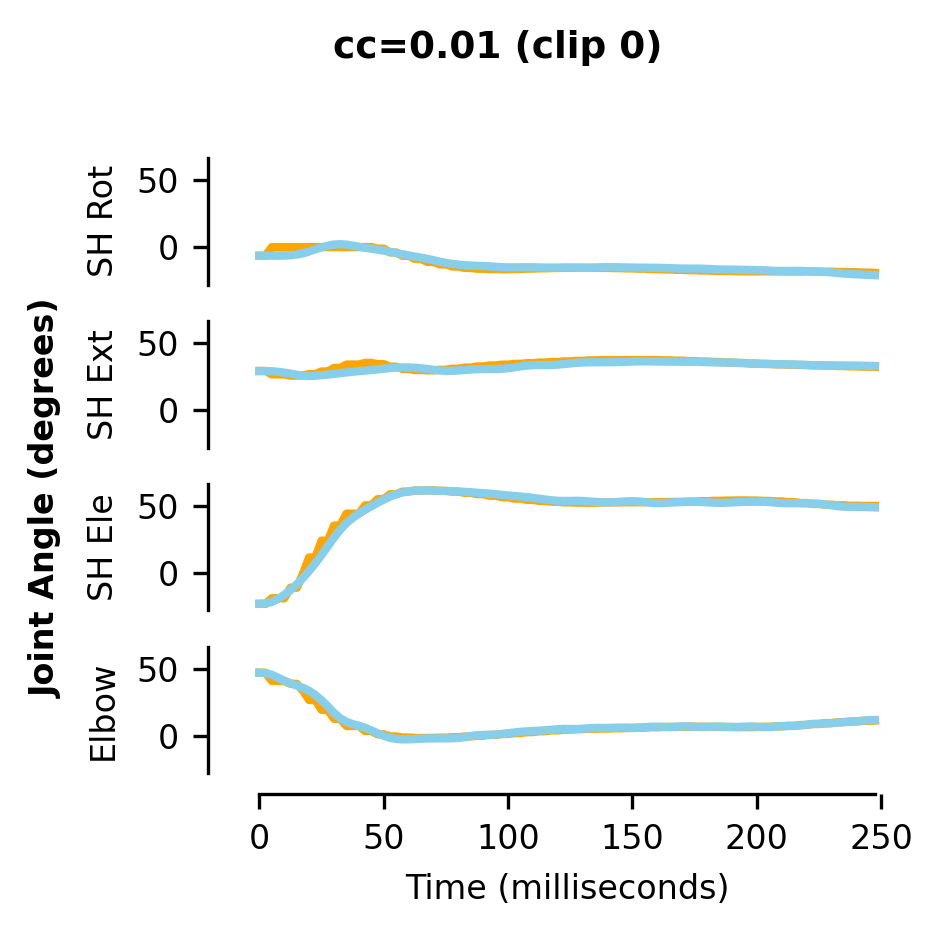

In [17]:
CLIP_ID = 0  # Change this to visualize different clips

# --- Kinematics Plot 1: cc=0.01 ---
plot_kinematics(
    qposes_ref, qposes_rollout, clip_id=CLIP_ID,
    title=f"cc=0.01 (clip {CLIP_ID})",
    save_path=f"notebooks/neurips_figures/data/kinematics_cc0.01_clip{CLIP_ID}.pdf",
)

Saved to notebooks/neurips_figures/data/kinematics_cc0.06_clip0.pdf


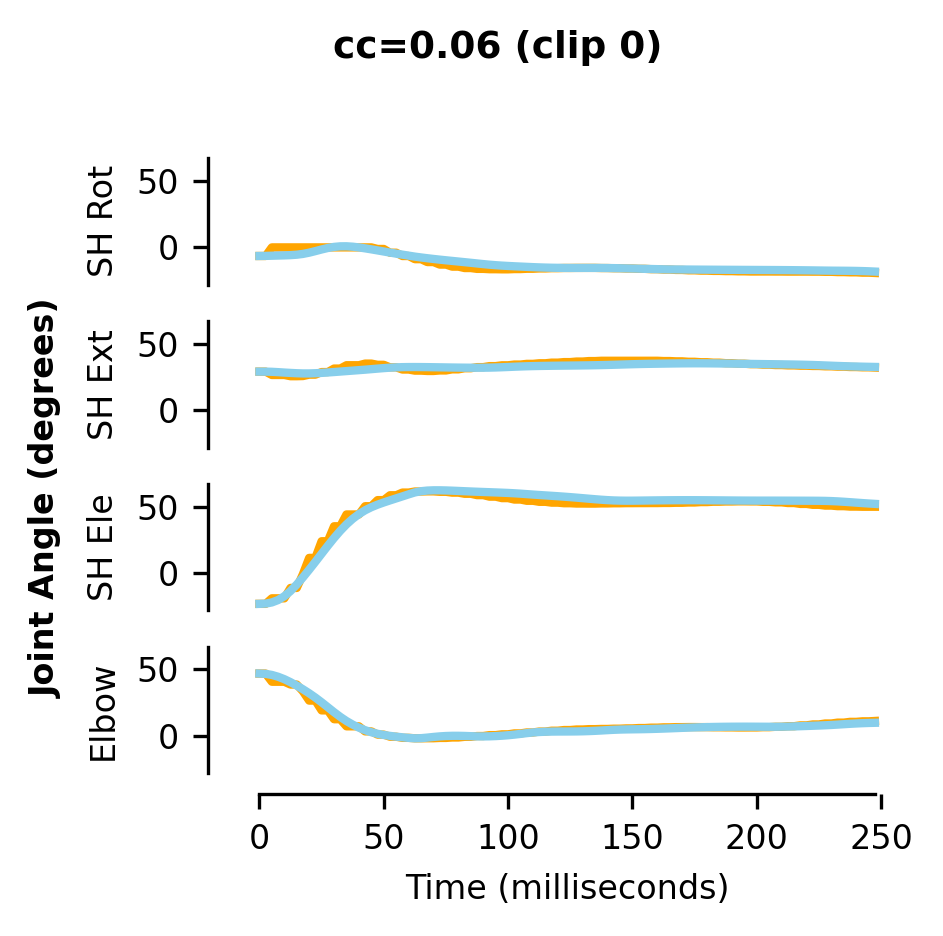

In [18]:
# --- Kinematics Plot 2: cc=0.06 ---
plot_kinematics(
    qposes_ref_v2, qposes_rollout_v2, clip_id=CLIP_ID,
    title=f"cc=0.06 (clip {CLIP_ID})",
    save_path=f"notebooks/neurips_figures/data/kinematics_cc0.06_clip{CLIP_ID}.pdf",
)

## 7. Side-by-Side Comparison

Direct comparison of both control cost variants in a single figure.

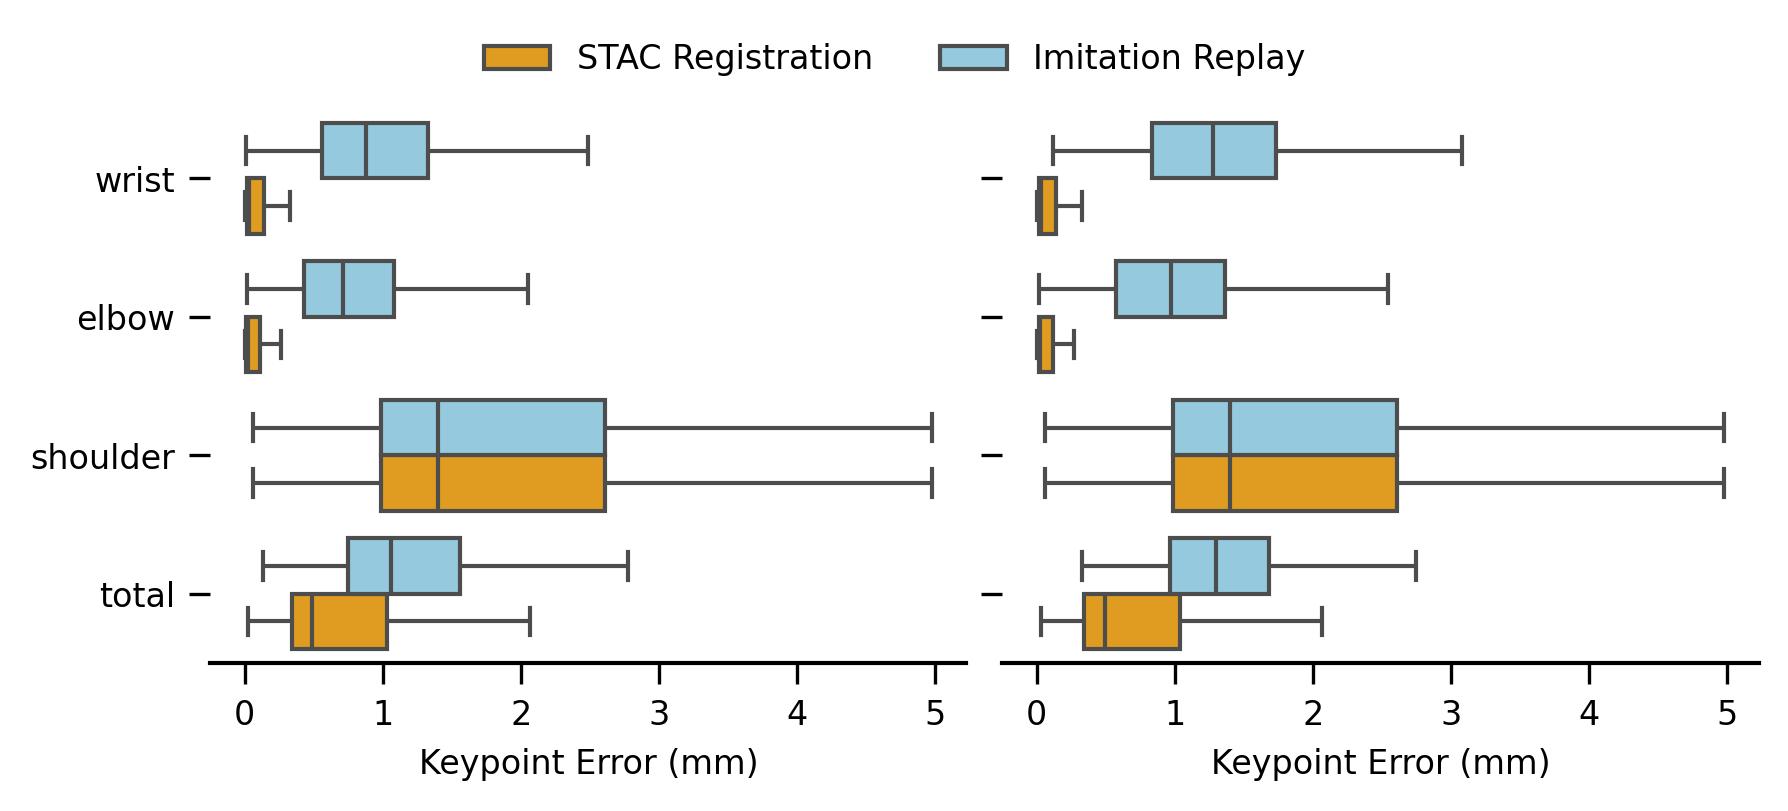

In [19]:
# --- Side-by-side boxplot comparison ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 2.5), sharey=True)
order = ["total", "shoulder", "elbow", "wrist"]
palette = {"STAC Registration": "orange", "Imitation Replay": "skyblue"}

for ax, df in [(ax1, df_v1), (ax2, df_v2)]:
    sns.boxplot(
        data=df, x="Keypoint Error (mm)", y="Body Part", hue="Method",
        palette=palette, orient="h", showfliers=False, ax=ax, order=order,
    )
    ax.set_xlabel("Keypoint Error (mm)", fontsize=8)
    ax.set_ylabel("")
    ax.tick_params(axis="both", which="major", labelsize=8, width=0.8, length=5)
    for spine in ax.spines.values():
        spine.set_linewidth(1)
    ax.invert_yaxis()
    if ax.get_legend():
        ax.get_legend().remove()
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=False)

# Shared legend
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=8, frameon=False,
           bbox_to_anchor=(0.5, 1.08))

plt.tight_layout()
plt.savefig("figures/kp_errors_comparison.pdf", bbox_inches="tight", dpi=300)
plt.savefig("figures/kp_errors_comparison.png", bbox_inches="tight", dpi=300)
plt.show()


## 9. Action Traces

Visualize control actions (muscle activations) from the imitation rollouts.
Compares cc=0.01 and cc=0.06 action patterns across all 46 clips.

In [20]:
# --- Action trace utilities ---
ACTUATOR_NAMES = JOINT_LABELS  # ["SH Rot", "SH Ext", "SH Ele", "Elbow"]

# Get ctrl data from rollouts
# rollout_data may have 'ctrl' key; if not, fall back to computing from qvel
ctrl_v1 = rollout_data.get("ctrl", None)
ctrl_v2 = rollout_data_v2.get("ctrl", None)

if ctrl_v1 is not None:
    ctrl_v1 = np.array(ctrl_v1)
    ctrl_v2 = np.array(ctrl_v2)
    print(f"ctrl_v1: {ctrl_v1.shape}, ctrl_v2: {ctrl_v2.shape}")
    n_actuators = ctrl_v1.shape[-1]
    # If more actuators than joints, take first 4
    if n_actuators > 4:
        print(f"  Truncating {n_actuators} actuators to first 4 joints")
        ctrl_v1 = ctrl_v1[..., :4]
        ctrl_v2 = ctrl_v2[..., :4]
else:
    # Compute finite-difference joint velocities as proxy for actions
    print("No ctrl in rollout data, using finite-diff joint velocities as proxy")
    dt = CTRL_DT
    ctrl_v1 = np.diff(qposes_rollout, axis=1) / dt
    ctrl_v2 = np.diff(qposes_rollout_v2, axis=1) / dt

n_steps_ctrl = ctrl_v1.shape[1]
time_ms_ctrl = np.arange(n_steps_ctrl) * CTRL_DT * 1e3
print(f"Action traces: {ctrl_v1.shape[0]} clips x {n_steps_ctrl} steps x {ctrl_v1.shape[-1]} actuators")

ctrl_v1: (46, 99, 12), ctrl_v2: (46, 99, 12)
  Truncating 12 actuators to first 4 joints
Action traces: 46 clips x 99 steps x 4 actuators


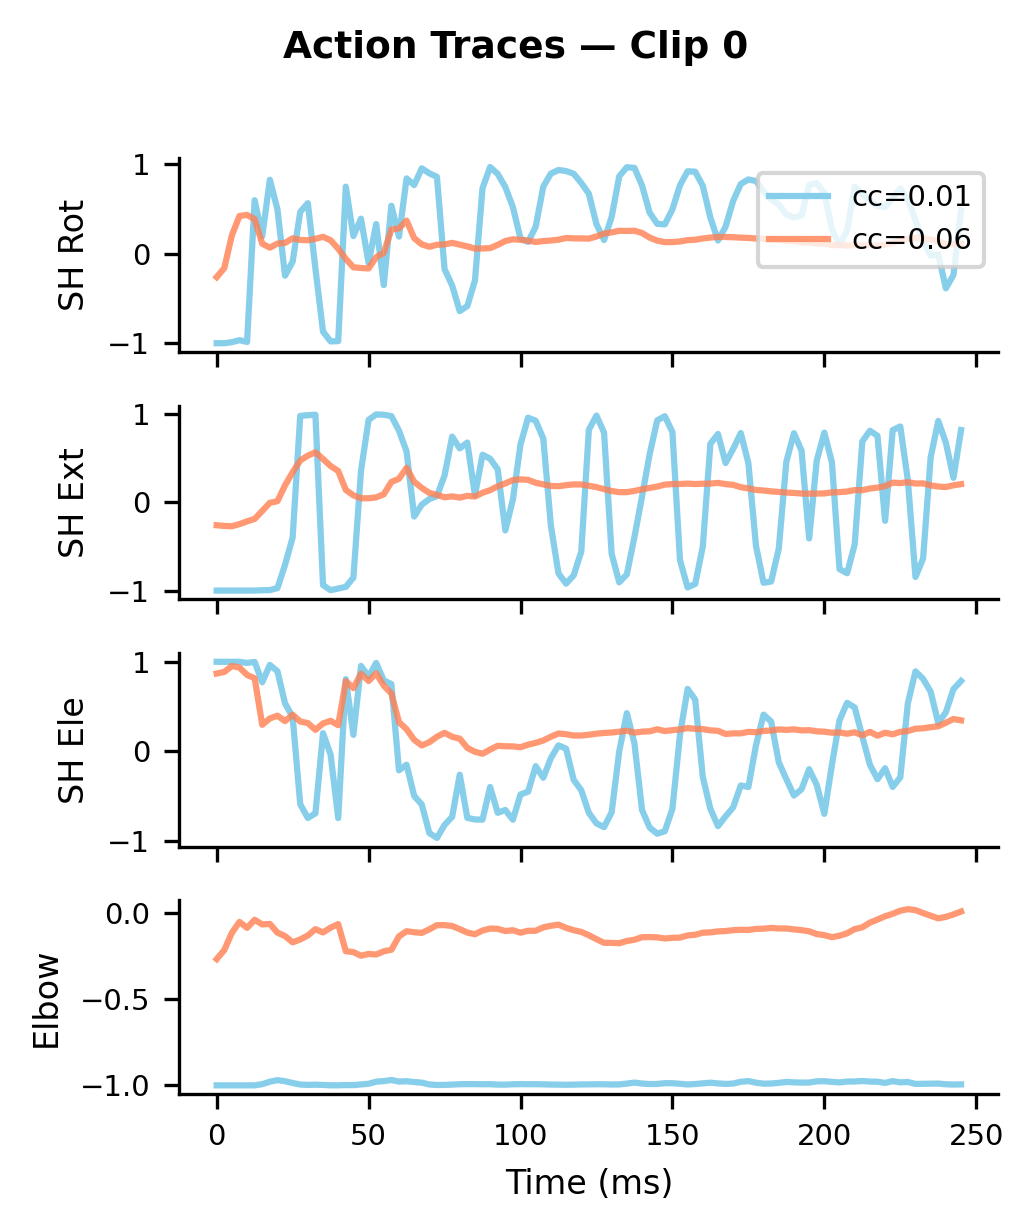

In [21]:
# --- Single clip action traces ---
CLIP_ID_ACTION = 0

fig, axes = plt.subplots(4, 1, figsize=(3.5, 4), sharex=True)
for i, (label, ax) in enumerate(zip(ACTUATOR_NAMES, axes)):
    ax.plot(time_ms_ctrl, ctrl_v1[CLIP_ID_ACTION, :, i], color="skyblue",
            linewidth=1.5, label="cc=0.01")
    ax.plot(time_ms_ctrl, ctrl_v2[CLIP_ID_ACTION, :, i], color="coral",
            linewidth=1.5, label="cc=0.06", alpha=0.8)
    ax.set_ylabel(label, fontsize=8)
    ax.tick_params(axis="both", labelsize=7)
    if i == 0:
        ax.legend(fontsize=7, loc="upper right")
    sns.despine(ax=ax, top=True, right=True)

axes[-1].set_xlabel("Time (ms)", fontsize=8)
fig.suptitle(f"Action Traces — Clip {CLIP_ID_ACTION}", fontsize=9, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"figures/action_traces_clip{CLIP_ID_ACTION}.pdf",
            bbox_inches="tight", dpi=300)
plt.savefig(f"figures/action_traces_clip{CLIP_ID_ACTION}.png",
            bbox_inches="tight", dpi=300)
plt.show()

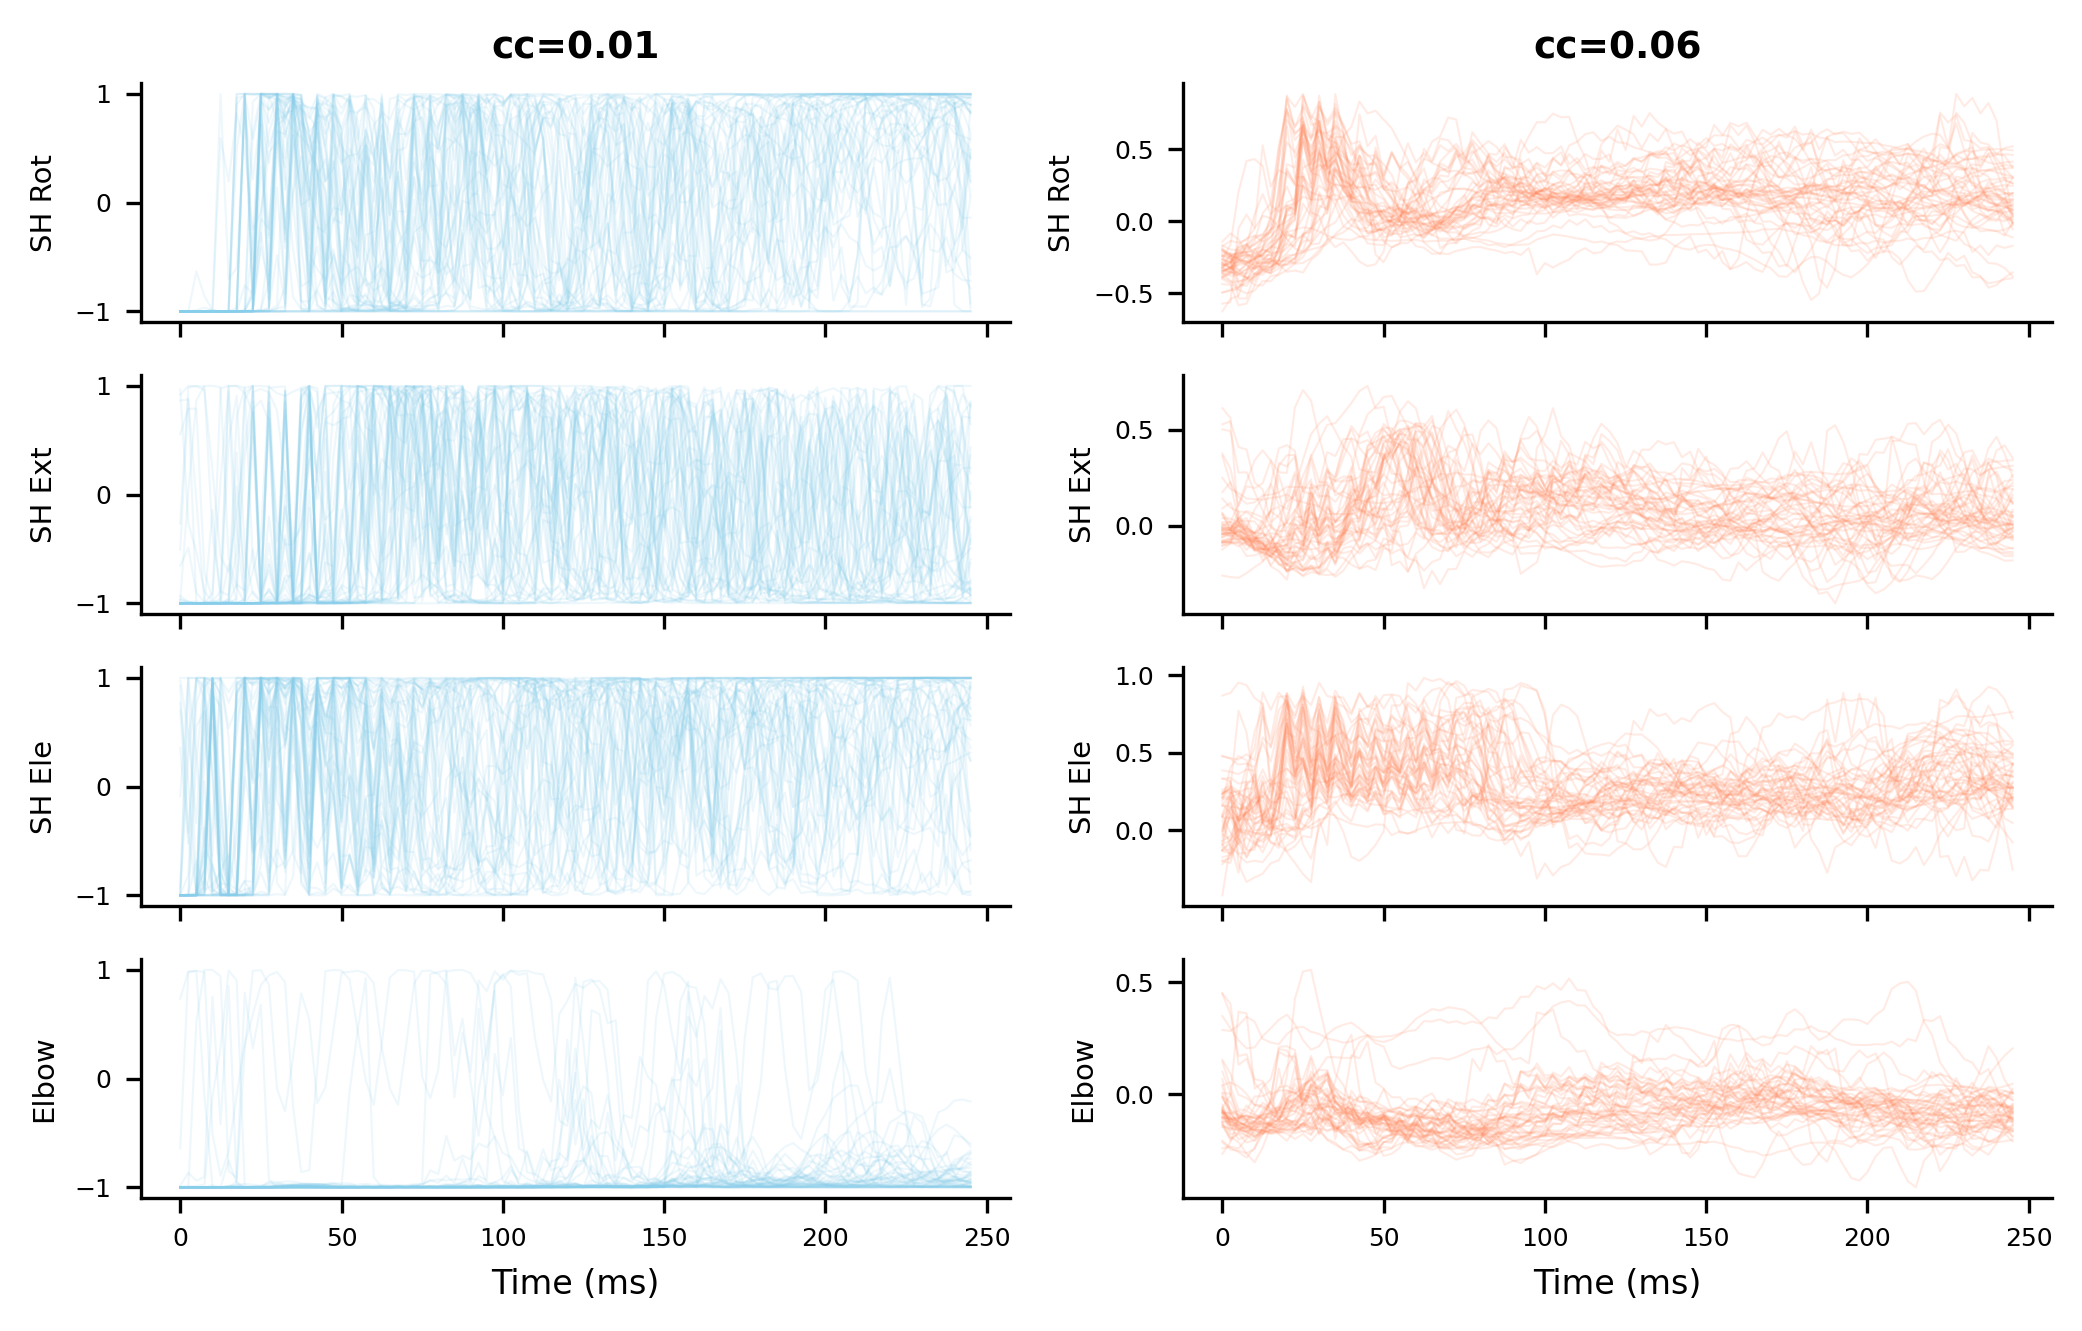

In [22]:
# --- All 46 clips overlaid (one figure per checkpoint) ---
fig, axes = plt.subplots(4, 2, figsize=(7, 4.5), sharex=True)

for col, (ctrl_data, ckpt_label, color) in enumerate([
    (ctrl_v1, "cc=0.01", "skyblue"),
    (ctrl_v2, "cc=0.06", "coral"),
]):
    for i, (label, ax) in enumerate(zip(ACTUATOR_NAMES, axes[:, col])):
        for clip_idx in range(ctrl_data.shape[0]):
            ax.plot(time_ms_ctrl, ctrl_data[clip_idx, :, i],
                    color=color, alpha=0.15, linewidth=0.5)
        ax.set_ylabel(label, fontsize=7)
        ax.tick_params(axis="both", labelsize=6)
        sns.despine(ax=ax, top=True, right=True)
    axes[0, col].set_title(ckpt_label, fontsize=9, fontweight="bold")
    axes[-1, col].set_xlabel("Time (ms)", fontsize=8)

plt.tight_layout()
plt.savefig("figures/action_traces_all_clips.pdf", bbox_inches="tight", dpi=300)
plt.savefig("figures/action_traces_all_clips.png", bbox_inches="tight", dpi=300)
plt.show()

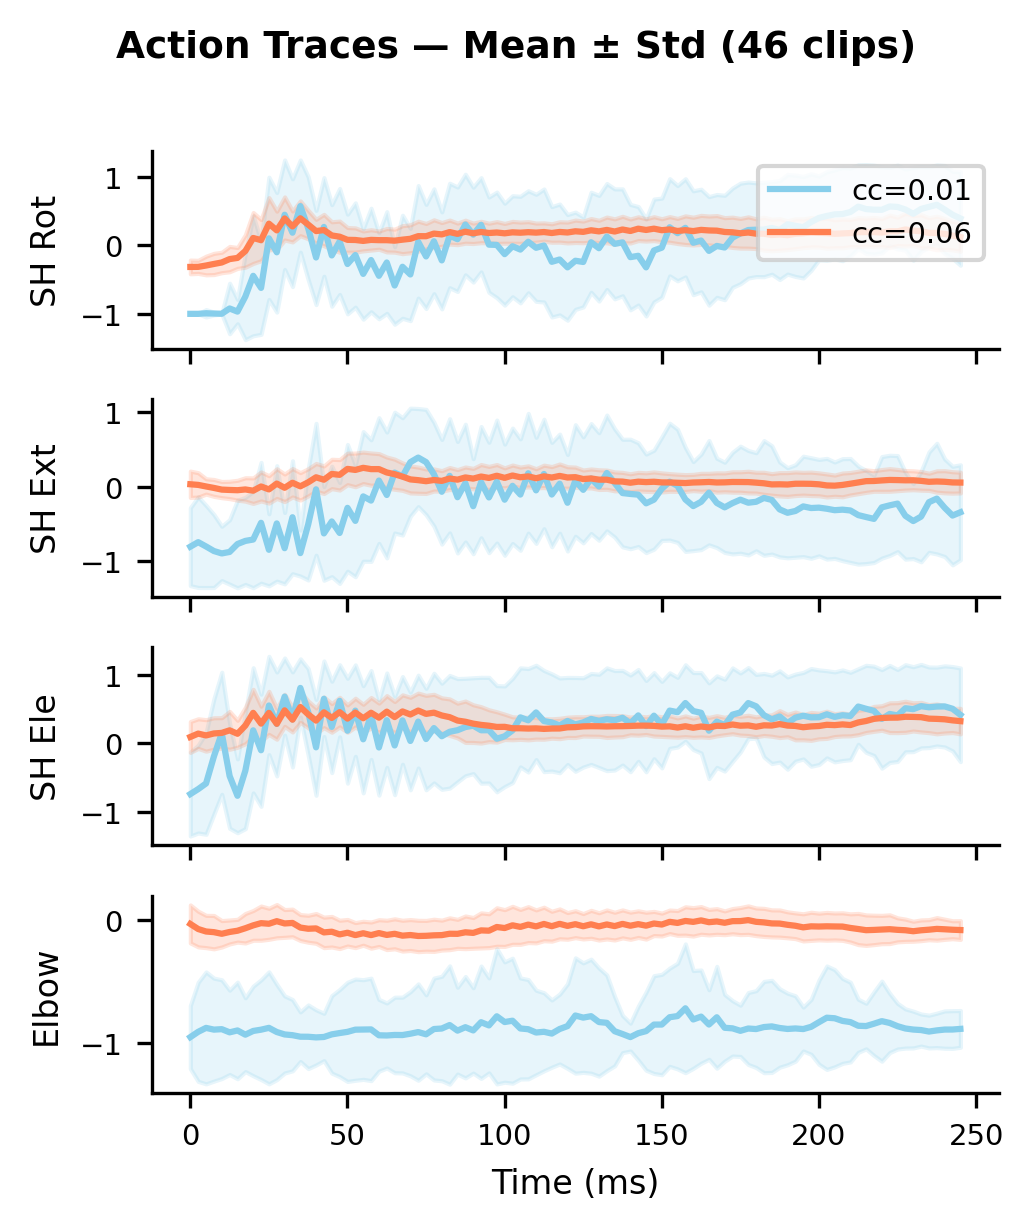

In [23]:
# --- Summary: mean +/- std across clips ---
fig, axes = plt.subplots(4, 1, figsize=(3.5, 4), sharex=True)

for i, (label, ax) in enumerate(zip(ACTUATOR_NAMES, axes)):
    mean_v1 = ctrl_v1[:, :, i].mean(axis=0)
    std_v1 = ctrl_v1[:, :, i].std(axis=0)
    mean_v2 = ctrl_v2[:, :, i].mean(axis=0)
    std_v2 = ctrl_v2[:, :, i].std(axis=0)

    ax.plot(time_ms_ctrl, mean_v1, color="skyblue", linewidth=1.5, label="cc=0.01")
    ax.fill_between(time_ms_ctrl, mean_v1 - std_v1, mean_v1 + std_v1,
                    color="skyblue", alpha=0.2)
    ax.plot(time_ms_ctrl, mean_v2, color="coral", linewidth=1.5, label="cc=0.06")
    ax.fill_between(time_ms_ctrl, mean_v2 - std_v2, mean_v2 + std_v2,
                    color="coral", alpha=0.2)

    ax.set_ylabel(label, fontsize=8)
    ax.tick_params(axis="both", labelsize=7)
    if i == 0:
        ax.legend(fontsize=7, loc="upper right")
    sns.despine(ax=ax, top=True, right=True)

axes[-1].set_xlabel("Time (ms)", fontsize=8)
fig.suptitle("Action Traces — Mean \u00b1 Std (46 clips)", fontsize=9, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("figures/action_traces_summary.pdf", bbox_inches="tight", dpi=300)
plt.savefig("figures/action_traces_summary.png", bbox_inches="tight", dpi=300)
plt.show()

## 8. Render Rollout Videos

Render videos of the imitation rollouts for visual inspection alongside kinematics.
Uses the SCAMPER rollout generator with `log_full_states=True` for rendering.

In [24]:
import mediapy as media
from omegaconf import OmegaConf
from scamper.analysis.rollout import create_rollout_generator

RENDER_CLIP_IDX = 0
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
GHOST_RGBA = [0.3, 0.8, 1.0, 0.4]  # translucent cyan, matching vnl-playground


def _build_ghost_model(xml_path, root_body="clavicle"):
    """Build a MuJoCo model with a ghost skeleton attached for reference rendering.

    Uses MjSpec to attach a recolored, non-colliding copy of the skeleton
    into the same scene (same approach as vnl-playground imitation rendering).
    """
    spec = mujoco.MjSpec.from_file(xml_path)
    ghost_spec = mujoco.MjSpec.from_file(xml_path)

    spawn_frame = spec.worldbody.add_frame(pos=[0, 0, 0], quat=[1, 0, 0, 0])
    ghost_body = spawn_frame.attach_body(
        ghost_spec.body(root_body), "", "-ghost"
    )

    def recolor_geoms(body, rgba):
        for g in body.geoms:
            g.rgba = rgba
            g.contype = 0
            g.conaffinity = 0
        for child in body.bodies:
            recolor_geoms(child, rgba)

    recolor_geoms(ghost_body, GHOST_RGBA)
    return spec.compile()


def render_rollout_video(checkpoint_path, checkpoint_step, clip_idx, label,
                         seed=42, render_ghost=True):
    """Render a rollout clip with optional translucent reference ghost."""
    ckpt = load_imitation_checkpoint(checkpoint_path, step=checkpoint_step)
    cfg = ckpt["cfg"]

    env = create_imitation_env(cfg, env_config_path=ENV_CONFIG_PATH)
    policy_fn = ckpt["make_policy"](deterministic=True, get_activation=False)

    if "env_config" not in cfg:
        ext_cfg = OmegaConf.load(ENV_CONFIG_PATH)
        cfg = OmegaConf.merge(ext_cfg, cfg)

    generate_rollout = create_rollout_generator(
        cfg=cfg,
        env=env,
        inference_fn=policy_fn,
        log_full_states=True,
        log_activations=False,
    )

    print(f"Running rollout for clip {clip_idx} ({label})...")
    single_rollout = generate_rollout(clip_idx=clip_idx, seed=seed)

    qposes_rollout = np.array(single_rollout["qposes_rollout"])  # (n_steps, 4)
    qposes_ref = np.array(single_rollout["qposes_ref"])          # (n_steps, 4)

    # Build render model (with or without ghost)
    if render_ghost:
        mj_model = _build_ghost_model(VNL_XML_PATH)
    else:
        mj_model = env.mj_model

    mj_model.vis.global_.offwidth = RENDER_WIDTH
    mj_model.vis.global_.offheight = RENDER_HEIGHT
    mj_data = mujoco.MjData(mj_model)
    renderer = mujoco.Renderer(mj_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

    n_steps = qposes_rollout.shape[0]
    ghost_str = " (with ghost)" if render_ghost else ""
    print(f"Rendering {RENDER_HEIGHT}x{RENDER_WIDTH} video from {n_steps} frames{ghost_str}...")

    frames = []
    for t in range(n_steps):
        if render_ghost:
            # Concatenate: [rollout_qpos, ghost_ref_qpos]
            mj_data.qpos[:] = np.concatenate([qposes_rollout[t], qposes_ref[t]])
        else:
            mj_data.qpos[:] = qposes_rollout[t]
        mujoco.mj_forward(mj_model, mj_data)
        renderer.update_scene(mj_data)
        frames.append(renderer.render().copy())

    renderer.close()

    frames = np.stack(frames)
    video_path = f"notebooks/neurips_figures/data/rollout_{label}_clip{clip_idx}.mp4"
    media.write_video(video_path, frames, fps=50)
    print(f"Saved to {video_path}")

    return frames


In [25]:
# --- Render cc=0.01 rollout ---
frames_v1 = render_rollout_video(
    CHECKPOINT_PATH, CHECKPOINT_STEP, RENDER_CLIP_IDX, label="cc0.01"
)
media.show_video(frames_v1, fps=50)

Loaded 46 clips with 50 frames each
  qpos shape: (46, 50, 4)
  xpos shape: (46, 50, 6, 3)
Running rollout for clip 0 (cc0.01)...
Rendering 480x640 video from 100 frames (with ghost)...
Saved to notebooks/neurips_figures/data/rollout_cc0.01_clip0.mp4


This browser does not support the video tag.


In [ ]:
# --- Render cc=0.06 rollout ---
frames_v2 = render_rollout_video(
    CHECKPOINT_PATH_V2, CHECKPOINT_STEP_V2, RENDER_CLIP_IDX, label="cc0.06"
)
media.show_video(frames_v2, fps=50)

Loaded 46 clips with 50 frames each
  qpos shape: (46, 50, 4)
  xpos shape: (46, 50, 6, 3)
Running rollout for clip 0 (cc0.06)...


## 10. Training Curve (from wandb)

/tmp/ipykernel_470235/3381607317.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  r3_df.assign(round="R3"),
/tmp/ipykernel_470235/3381607317.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  r4_df.assign(round="R4"),
/tmp/ipykernel_470235/3381607317.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.c

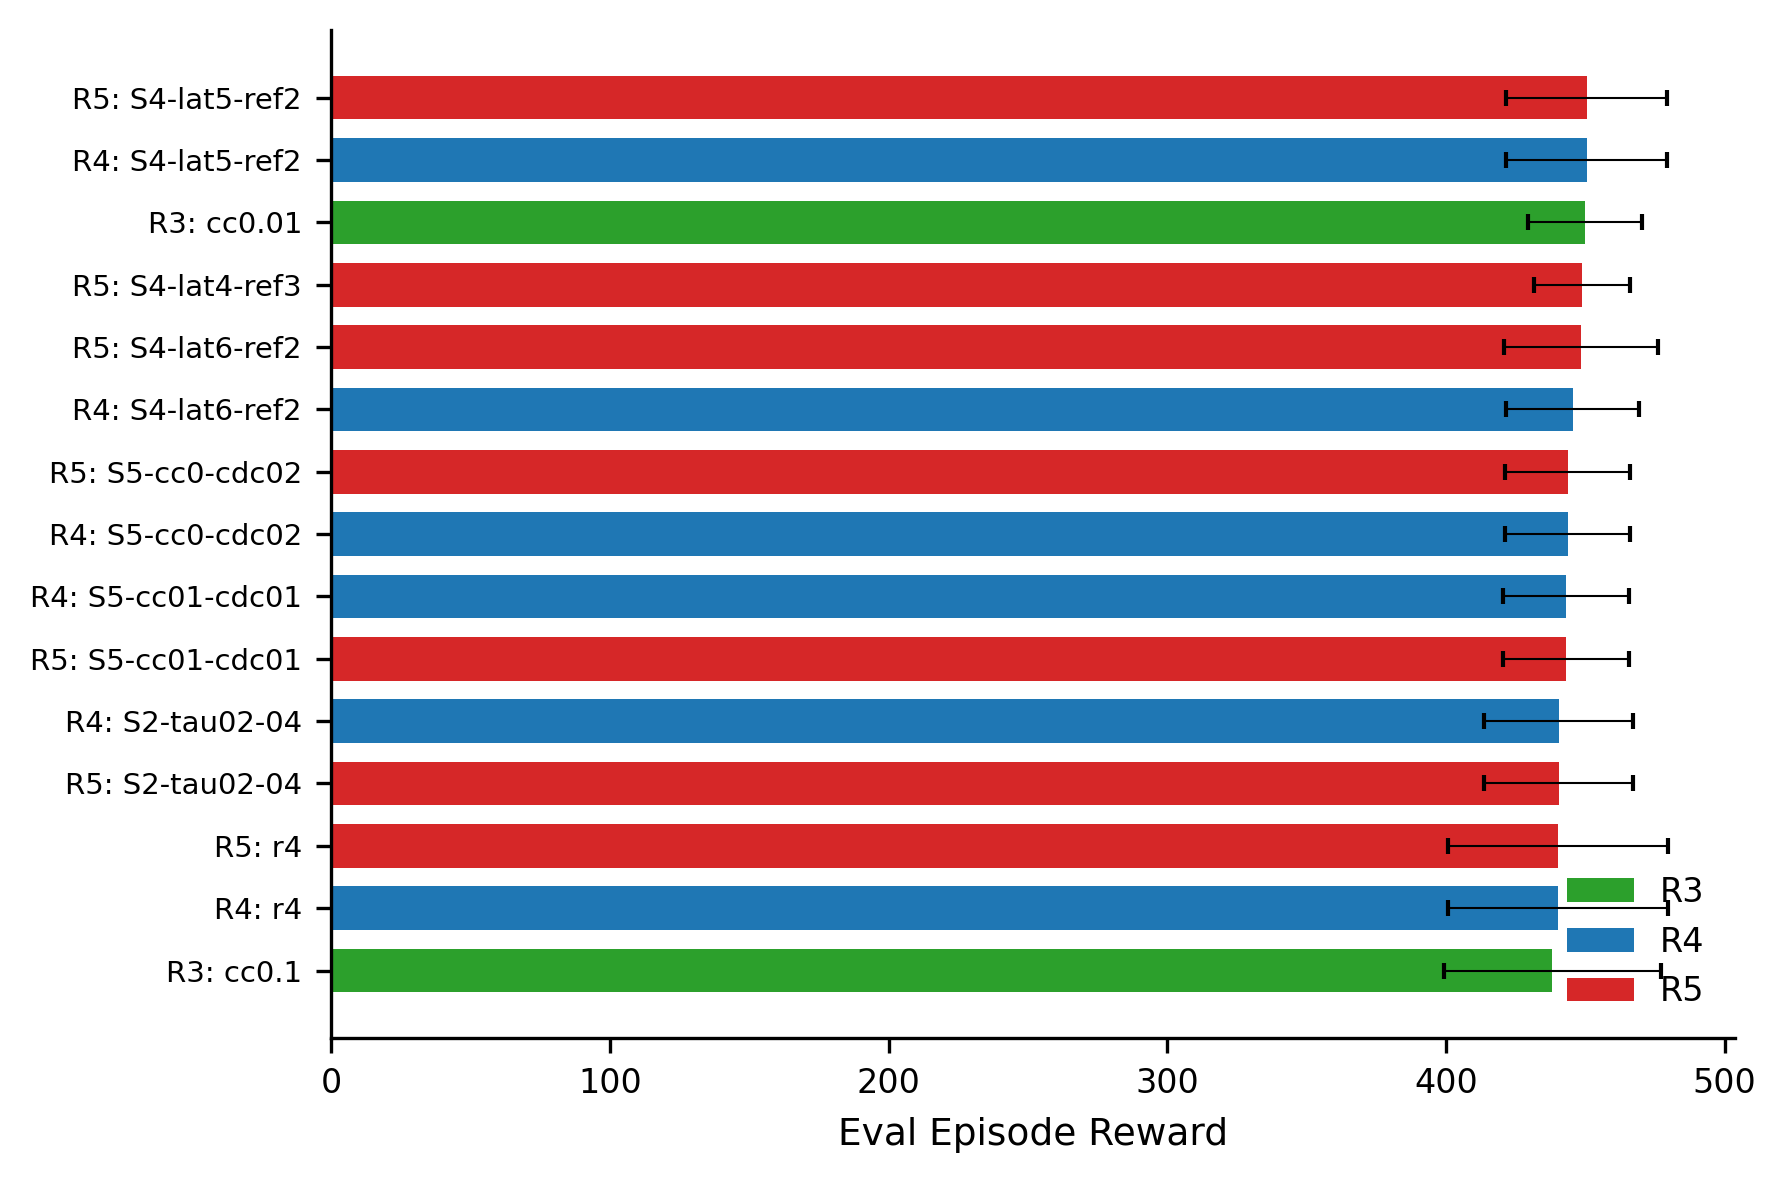


Top 5 runs by eval reward:
  R5: S4-lat5-ref2                         reward=450.5 steps=800M
  R4: S4-lat5-ref2                         reward=450.5 steps=800M
  R3: cc0.01                               reward=450.0 steps=1000M
  R5: S4-lat4-ref3                         reward=448.8 steps=800M
  R5: S4-lat6-ref2                         reward=448.4 steps=800M


In [ ]:
# --- Training runs summary (from wandb CSV exports) ---
# Source: https://wandb.ai/vnl/vnl-mjx-rl
# CSV paths: /root/vast/eric/vnl-playground/{wandb_r4.csv, round3.csv, r5early.csv}

r4_df = pd.read_csv("/root/vast/eric/vnl-playground/wandb_r4.csv")
r3_df = pd.read_csv("/root/vast/eric/vnl-playground/round3.csv")
r5_df = pd.read_csv("/root/vast/eric/vnl-playground/r5early.csv")

# Combine all rounds
all_runs = pd.concat([
    r3_df.assign(round="R3"),
    r4_df.assign(round="R4"),
    r5_df.assign(round="R5"),
], ignore_index=True)

# Filter to runs with valid reward
all_runs = all_runs.dropna(subset=["eval/episode_reward"])

# Short name: extract the key tag
def short_name(row):
    tags = str(row.get("Tags", ""))
    name = str(row.get("Name", ""))
    # Use first tag component
    parts = [t.strip() for t in tags.split(",")]
    label = parts[0] if parts else name[:30]
    return f"{row['round']}: {label}"

all_runs["label"] = all_runs.apply(short_name, axis=1)

# Top 15 by reward
top = all_runs.nlargest(15, "eval/episode_reward").copy()
top = top.sort_values("eval/episode_reward", ascending=True)

fig, ax = plt.subplots(figsize=(6, 4))

colors = {"R3": "#2ca02c", "R4": "#1f77b4", "R5": "#d62728"}
bar_colors = [colors.get(r, "gray") for r in top["round"]]

bars = ax.barh(range(len(top)), top["eval/episode_reward"], color=bar_colors, height=0.7)

# Error bars if available
if "eval/episode_reward_std" in top.columns:
    ax.errorbar(top["eval/episode_reward"].values, range(len(top)),
                xerr=top["eval/episode_reward_std"].values,
                fmt="none", ecolor="black", elinewidth=0.5, capsize=2)

ax.set_yticks(range(len(top)))
ax.set_yticklabels(top["label"].values, fontsize=7)
ax.set_xlabel("Eval Episode Reward", fontsize=9)
ax.tick_params(axis="x", labelsize=8)
sns.despine(ax=ax, top=True, right=True)

# Legend for rounds
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=r) for r, c in colors.items()]
ax.legend(handles=legend_elements, fontsize=8, loc="lower right", frameon=False)

plt.tight_layout()
plt.savefig("figures/training_runs_comparison.pdf", bbox_inches="tight", dpi=300)
plt.savefig("figures/training_runs_comparison.png", bbox_inches="tight", dpi=300)
plt.show()

# Print top 5
print("\nTop 5 runs by eval reward:")
for _, row in top.tail(5).iloc[::-1].iterrows():
    print(f"  {row['label']:40s} reward={row['eval/episode_reward']:.1f} "
          f"steps={row.get('total_steps', 0)/1e6:.0f}M")
